**TỔNG QUAN EDA**

*   EDA từ câu hỏi kinh doanh/bài toán, vì nó quyết định nên đào sâu khía cạnh nào thay vì vẽ mọi biểu đồ có thể


1.   1. Mô tả tổng quan bộ dữ liệu

Phạm vi: số khách hàng, số bản ghi, giai đoạn thời gian, nguồn dữ liệu
Đơn vị quan sát: mỗi dòng là một khách hàng, một khoản vay hay một kỳ báo cáo
Danh sách biến (data dictionary): tên, ý nghĩa, kiểu dữ liệu, đơn vị
Tình trạng dữ liệu: tỷ lệ thiếu, trùng lặp, giá trị bất thường ở mức tổng quát

2. Mô tả biến số (định lượng)
Với mỗi biến như doanh thu, tổng tài sản, dư nợ, số năm hoạt động:

Đo xu hướng trung tâm: mean, median, mode
Đo độ phân tán: std, min, max, khoảng biến thiên, IQR
Phân vị: P1, P5, P25, P50, P75, P95, P99 (rất hữu ích với dữ liệu tài chính lệch)
Hình dạng phân phối: skewness, kurtosis
Biểu đồ: histogram (nên thêm bản thang log), boxplot

3. Mô tả biến phân loại
Với các biến như ngành nghề, loại hình doanh nghiệp, quy mô, khu vực, chi nhánh, nhóm nợ:

Số lượng và tỷ lệ % từng nhóm
Số nhóm khác nhau, nhóm chiếm đa số, nhóm quá nhỏ cần gộp
Biểu đồ: bar chart, Pareto chart (xem vài nhóm chiếm phần lớn)

4. Mô tả theo nhóm (phân khúc)
Đây là phần mang lại nhiều thông tin nhất trong EDA mô tả:

Thống kê biến số theo từng nhóm: ví dụ doanh thu median theo ngành, dư nợ trung bình theo quy mô
Bảng chéo giữa hai biến phân loại: ngành × quy mô, khu vực × nhóm nợ
Cơ cấu: tỷ trọng số lượng khách hàng so với tỷ trọng dư nợ theo từng nhóm (thường rất khác nhau)

5. Mô tả mức độ tập trung
Đặc biệt quan trọng với KHDN:

Top 10, top 20 khách hàng chiếm bao nhiêu % dư nợ
Đường cong Lorenz, hệ số Gini hoặc chỉ số HHI cho mức tập trung theo khách hàng, ngành
Ngành nào, chi nhánh nào chiếm tỷ trọng lớn

6. Mô tả theo thời gian
Nếu có nhiều kỳ dữ liệu:

Số lượng khách hàng, tổng dư nợ, tỷ lệ nợ xấu qua các tháng/quý/năm
Khách hàng mới, khách hàng rời đi
Thay đổi cơ cấu theo ngành, quy mô qua thời gian
Biểu đồ: line chart, stacked area chart

7. Mô tả mối quan hệ cơ bản
Ở mức mô tả, không cần kiểm định sâu:

Ma trận tương quan giữa các biến tài chính chính
Scatter plot cho vài cặp biến quan trọng (doanh thu – dư nợ, tổng tài sản – vốn chủ sở hữu)

##Một báo cáo EDA mô tả gọn thường gồm:


1.   Giới thiệu bộ dữ liệu và phạm vi
2. Chất lượng dữ liệu
3. Đặc điểm khách hàng (quy mô, ngành, khu vực)
4. Đặc điểm tài chính và tín dụng5.
5. Cơ cấu và mức độ tập trung
6. Biến động theo thời gian
7. Các phát hiện chính (key findings) và lưu ý cho bước phân tích tiếp theo






# EDA MÔ TẢ - DỮ LIỆU KHÁCH HÀNG DOANH NGHIỆP AIV BANK

**Đầu vào:** `AIV_Bank_KHDN_Dataset.xlsx` (star schema: dim_* và fact_*)

**Đầu ra:** thư mục `eda_output/`
- `bao_cao_eda_mo_ta.xlsx`: toàn bộ bảng thống kê, mỗi phần một sheet
- `charts/*.png`: biểu đồ

**Quy tắc nghiệp vụ được tôn trọng trong code:**
- Dư nợ là chỉ tiêu SỐ DƯ → chỉ lấy tại một ngày chốt, KHÔNG cộng qua các tháng.
- NII / NFI / TOI là chỉ tiêu PHÁT SINH → được cộng dồn theo kỳ (tháng, YTD).
- Tỷ lệ OD2, OD3-5 = dư nợ nhóm nợ / tổng dư nợ.

**Cách chạy:** đặt notebook cùng thư mục với file Excel, chọn *Run All* (khoảng 1–2 phút).
Thư viện cần có: pandas, numpy, matplotlib, openpyxl.

## 🔑 TÓM TẮT NHANH - DỮ LIỆU NÓI GÌ?

| Chỉ tiêu | Giá trị (30/06/2026) |
|---|---|
| Số khách hàng | **10.000** KH, trong đó **8.778** KH còn dư nợ (87,8%) |
| Số hợp đồng | **31.104** hợp đồng, **11.073** hợp đồng đang hiệu lực |
| Tổng dư nợ | **98.367 tỷ đồng** (+10,9% so với 30/06/2025) |
| Dư nợ mỗi KH | Trung bình **11,2 tỷ**, nhưng một nửa số KH vay dưới **2,8 tỷ** |
| Nợ xấu (nhóm 3-5) | **2,63%** tổng dư nợ; nợ nhóm 2: **0,94%** |
| Thu nhập 6 tháng đầu 2026 | TOI **1.165 tỷ** (NII 803 tỷ + NFI 363 tỷ) |

**3 ý chính cần nhớ:**
1. **Đông khách nhỏ, nhiều tiền ở khách lớn:** 83% số KH là MICRO/SMALL nhưng chỉ chiếm 34% dư nợ; 6% KH lớn (UPPER, BIGCORP) nắm 44% dư nợ.
2. **Dư nợ tăng đều, số KH có dư nợ giảm nhẹ:** dư nợ tăng từ 69.478 lên 98.367 tỷ trong 30 tháng, còn số KH có dư nợ giảm từ 9.180 xuống 8.778.
3. **Nợ xấu ổn định rồi tăng trở lại:** quanh 2,1–2,2% suốt năm 2025, tăng lên 2,63% vào 06/2026, cao hơn ở ngành Bất động sản và vay trung dài hạn.


In [3]:
from google.colab import files

uploaded = files.upload()

Saving AIV_Bank_KHDN_Dataset.xlsx to AIV_Bank_KHDN_Dataset.xlsx


## 0. THIẾT LẬP

In [1]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from openpyxl.utils import get_column_letter

FILE = "AIV_Bank_KHDN_Dataset.xlsx"
OUT_DIR = Path("eda_output")
CHART_DIR = OUT_DIR / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

TY = 1e9  # quy đổi VND -> tỷ đồng
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

matplotlib.rcParams.update({
    "font.family": "DejaVu Sans",        # hiển thị được tiếng Việt
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})
C_MAIN, C_ACCENT, C_RED, C_GREY = "#2a6f97", "#f4a259", "#c0392b", "#9aa5b1"

REPORT = {}  # tên sheet -> DataFrame, ghi ra Excel ở cuối


def save_table(name, df, show=True):
    """Lưu bảng vào báo cáo Excel và in ra màn hình."""
    REPORT[name[:31]] = df
    if show:
        print(f"\n--- {name} ---")
        display(df.head(30))


def save_chart(fig, name):
    fig.tight_layout()
    fig.savefig(CHART_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def section(title):
    print("\n" + "=" * 90 + f"\n{title}\n" + "=" * 90)

## 1. ĐỌC DỮ LIỆU

In [4]:
section("1. ĐỌC DỮ LIỆU")
xls = pd.ExcelFile(FILE)
TABLES = [s for s in xls.sheet_names if s.startswith(("dim_", "fact_"))]
data = {s: xls.parse(s) for s in TABLES}
print("Các bảng:", TABLES)

cust = data["dim_customer"]
loan = data["dim_loan_contract"]
branch = data["dim_branch"]
seg = data["dim_segment"]
ind = data["dim_industry"]
prod = data["dim_product"]
dg = data["dim_debt_group"]
camp = data["dim_campaign"]
bal = data["fact_loan_balance"]
inc = data["fact_income_monthly"]
cic = data["fact_debt_group_cic"]
due = data["fact_due_soon"]


1. ĐỌC DỮ LIỆU
Các bảng: ['dim_customer', 'dim_loan_contract', 'dim_branch', 'dim_segment', 'dim_industry', 'dim_product', 'dim_debt_group', 'dim_campaign', 'dim_date', 'fact_loan_balance', 'fact_income_monthly', 'fact_plan', 'fact_due_soon', 'fact_debt_group_cic']


## 2. TỔNG QUAN & CHẤT LƯỢNG DỮ LIỆU

In [5]:
section("2. TỔNG QUAN & CHẤT LƯỢNG DỮ LIỆU")

PRIMARY_KEYS = {
    "dim_customer": ["cif"], "dim_loan_contract": ["contract_id"],
    "dim_branch": ["branch_id"], "dim_segment": ["segment_id"],
    "dim_industry": ["industry_id"], "dim_product": ["product_id"],
    "dim_debt_group": ["debt_group_id"], "dim_campaign": ["campaign_id"],
    "dim_date": ["date"], "fact_loan_balance": ["snapshot_date", "contract_id"],
    "fact_income_monthly": ["month_id", "contract_id"],
    "fact_plan": ["month_id", "branch_id"],
    "fact_due_soon": ["contract_id"], "fact_debt_group_cic": ["cif"],
}

overview = []
for name, df in data.items():
    key = PRIMARY_KEYS.get(name, [])
    overview.append({
        "bảng": name,
        "số dòng": len(df),
        "số cột": df.shape[1],
        "ô bị thiếu": int(df.isna().sum().sum()),
        "dòng trùng hoàn toàn": int(df.duplicated().sum()),
        "khóa chính": ", ".join(key),
        "khóa bị trùng": int(df.duplicated(subset=key).sum()) if key else None,
    })
save_table("01_tong_quan_bang", pd.DataFrame(overview))

# Chi tiết từng cột: kiểu dữ liệu, % thiếu, số giá trị khác nhau, ví dụ
col_profile = []
for name, df in data.items():
    if name == "dim_date":
        continue
    for c in df.columns:
        s = df[c]
        col_profile.append({
            "bảng": name, "cột": c, "kiểu": str(s.dtype),
            "% thiếu": round(s.isna().mean() * 100, 2),
            "số giá trị khác nhau": s.nunique(),
            "ví dụ": ", ".join(map(str, s.dropna().unique()[:3])),
        })
col_profile = pd.DataFrame(col_profile)
save_table("02_ho_so_cot", col_profile, show=False)
print("\nCột có giá trị thiếu:")
print(col_profile[col_profile["% thiếu"] > 0][["bảng", "cột", "% thiếu"]].to_string(index=False))
print("(close_date / exit_reason / rolled_from_contract_id thiếu là HỢP LÝ: hợp đồng còn hiệu lực"
      " hoặc không phải tái tục)")

# Toàn vẹn khóa ngoại
fk_checks = [
    ("dim_loan_contract.cif", loan["cif"], cust["cif"]),
    ("dim_loan_contract.branch_id", loan["branch_id"], branch["branch_id"]),
    ("dim_loan_contract.product_id", loan["product_id"], prod["product_id"]),
    ("dim_loan_contract.campaign_id", loan["campaign_id"], camp["campaign_id"]),
    ("dim_customer.segment_id", cust["segment_id"], seg["segment_id"]),
    ("dim_customer.industry_id", cust["industry_id"], ind["industry_id"]),
    ("dim_customer.home_branch_id", cust["home_branch_id"], branch["branch_id"]),
    ("fact_loan_balance.contract_id", bal["contract_id"], loan["contract_id"]),
    ("fact_loan_balance.debt_group_id", bal["debt_group_id"], dg["debt_group_id"]),
    ("fact_income_monthly.contract_id", inc["contract_id"], loan["contract_id"]),
]
fk = pd.DataFrame([{"khóa ngoại": n, "số dòng không khớp": int((~a.isin(b)).sum())}
                   for n, a, b in fk_checks])
save_table("03_khoa_ngoai", fk)


2. TỔNG QUAN & CHẤT LƯỢNG DỮ LIỆU

--- 01_tong_quan_bang ---


,bảng,số dòng,số cột,ô bị thiếu,dòng trùng hoàn toàn,khóa chính,khóa bị trùng
0,dim_customer,10000,18,0,0,cif,0
1,dim_loan_contract,31104,27,38132,0,contract_id,0
2,dim_branch,78,8,0,0,branch_id,0
3,dim_segment,7,7,0,0,segment_id,0
4,dim_industry,22,3,0,0,industry_id,0
5,dim_product,3,3,0,0,product_id,0
6,dim_debt_group,5,5,0,0,debt_group_id,0
7,dim_campaign,17,8,2,0,campaign_id,0
8,dim_date,1277,18,0,0,date,0
9,fact_loan_balance,333882,11,0,0,"snapshot_date, contract_id",0



Cột có giá trị thiếu:
             bảng                     cột  % thiếu
dim_loan_contract              close_date    35.60
dim_loan_contract             exit_reason    35.60
dim_loan_contract rolled_from_contract_id    41.05
dim_loan_contract                 ltv_pct    10.34
     dim_campaign              valid_from     5.88
     dim_campaign                valid_to     5.88
(close_date / exit_reason / rolled_from_contract_id thiếu là HỢP LÝ: hợp đồng còn hiệu lực hoặc không phải tái tục)

--- 03_khoa_ngoai ---


,khóa ngoại,số dòng không khớp
0,dim_loan_contract.cif,0
1,dim_loan_contract.branch_id,0
2,dim_loan_contract.product_id,0
3,dim_loan_contract.campaign_id,0
4,dim_customer.segment_id,0
5,dim_customer.industry_id,0
6,dim_customer.home_branch_id,0
7,fact_loan_balance.contract_id,0
8,fact_loan_balance.debt_group_id,0
9,fact_income_monthly.contract_id,0


### 📝 Nhận xét - Chất lượng dữ liệu
- Bộ dữ liệu gồm **14 bảng** (9 bảng dim, 5 bảng fact), tổng khoảng **723 nghìn dòng**.
- **Không có dòng trùng**, khóa chính không bị trùng, mọi khóa ngoại đều khớp → có thể nối các bảng với nhau mà không mất dữ liệu.
- Các ô bị thiếu đều **có lý do nghiệp vụ**, không phải lỗi:
  - `close_date`, `exit_reason` trống (35,6%) vì hợp đồng **vẫn còn hiệu lực**.
  - `rolled_from_contract_id` trống (41%) vì hợp đồng **không phải tái tục**.
  - `ltv_pct` trống (10,3%) vì khoản vay **tín chấp**, không có tài sản bảo đảm.

→ Dữ liệu sạch, dùng được ngay; không cần điền giá trị thiếu.

## 3. CHUẨN BỊ BẢNG PHÂN TÍCH

In [6]:
# Gắn thuộc tính dimension vào khách hàng & hợp đồng
cust_x = (cust.merge(seg[["segment_id", "segment", "segment_lv2"]], on="segment_id")
              .merge(ind, on="industry_id")
              .merge(branch[["branch_id", "branch_name", "region"]],
                     left_on="home_branch_id", right_on="branch_id")
              .drop(columns="branch_id"))
SNAP_DATE = bal["snapshot_date"].max()
cust_x["years_with_bank"] = (SNAP_DATE - cust_x["customer_since"]).dt.days / 365.25
cust_x["company_age"] = SNAP_DATE.year - cust_x["established_year"]
cust_x["revenue_bn"] = cust_x["annual_revenue_vnd"] / TY

SEG_ORDER = seg.sort_values("segment_id")["segment"].tolist()
RATING_ORDER = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]

loan_x = (loan.merge(prod, on="product_id")
              .merge(cust_x[["cif", "segment", "segment_lv2", "industry_name", "industry_group",
                             "credit_rating"]], on="cif")
              .merge(branch[["branch_id", "branch_name", "region", "branch_type"]], on="branch_id")
              .merge(camp[["campaign_id", "category"]].rename(columns={"category": "campaign_category"}),
                     on="campaign_id"))

# Bảng số dư đầy đủ thuộc tính (dùng cho cơ cấu & xu hướng)
bal_x = (bal.merge(loan_x[["contract_id", "cif", "segment", "segment_lv2", "industry_name",
                           "industry_group", "branch_name", "region", "term_group", "ccy",
                           "product_code", "collateral_type", "credit_rating"]], on="contract_id")
            .merge(dg[["debt_group_id", "debt_group_code", "is_od2", "is_od35"]], on="debt_group_id"))
bal_now = bal_x[bal_x["snapshot_date"] == SNAP_DATE].copy()
print(f"\nNgày chốt mới nhất: {SNAP_DATE:%d/%m/%Y} | số hợp đồng còn dư nợ: {len(bal_now):,}"
      f" | tổng dư nợ: {bal_now['balance_vnd'].sum() / TY:,.0f} tỷ")


Ngày chốt mới nhất: 30/06/2026 | số hợp đồng còn dư nợ: 11,073 | tổng dư nợ: 98,367 tỷ


## 4. HÀM THỐNG KÊ MÔ TẢ DÙNG CHUNG

In [7]:
def describe_numeric(df, cols, labels=None):
    """Thống kê mô tả đầy đủ cho biến số, kèm phân vị và độ lệch."""
    rows = []
    for c in cols:
        s = df[c].dropna()
        rows.append({
            "biến": (labels or {}).get(c, c), "n": len(s),
            "mean": s.mean(), "median": s.median(), "std": s.std(),
            "min": s.min(), "P1": s.quantile(.01), "P5": s.quantile(.05),
            "P25": s.quantile(.25), "P75": s.quantile(.75), "P95": s.quantile(.95),
            "P99": s.quantile(.99), "max": s.max(), "IQR": s.quantile(.75) - s.quantile(.25),
            "CV (std/mean)": s.std() / s.mean() if s.mean() else np.nan,
            "skewness": s.skew(), "kurtosis": s.kurt(),
            "% bằng 0": (s == 0).mean() * 100,
            "số outlier (1.5 IQR)": int(((s < s.quantile(.25) - 1.5 * (s.quantile(.75) - s.quantile(.25))) |
                                         (s > s.quantile(.75) + 1.5 * (s.quantile(.75) - s.quantile(.25)))).sum()),
        })
    return pd.DataFrame(rows).set_index("biến")


def freq_table(series, order=None, value=None, value_name="dư nợ (tỷ)"):
    """Bảng tần suất cho biến phân loại; nếu có `value` thì thêm tỷ trọng theo giá trị (vd. dư nợ)."""
    out = series.value_counts().rename("số lượng").to_frame()
    out["% số lượng"] = out["số lượng"] / out["số lượng"].sum() * 100
    if value is not None:
        v = value.groupby(series).sum()
        out[value_name] = v / TY
        out[f"% {value_name}"] = v / v.sum() * 100
    if order:
        out = out.reindex([o for o in order if o in out.index])
    out.index.name = series.name
    return out


def plot_hist_log(s, title, fname, xlabel):
    """Histogram thang gốc và thang log10 cạnh nhau (biến tiền tệ thường lệch phải)."""
    s = s.dropna()
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].hist(s, bins=50, color=C_MAIN)
    ax[0].axvline(s.median(), color=C_ACCENT, ls="--", label=f"median = {s.median():,.1f}")
    ax[0].axvline(s.mean(), color=C_RED, ls=":", label=f"mean = {s.mean():,.1f}")
    ax[0].set(title=f"{title} (thang gốc)", xlabel=xlabel, ylabel="Số lượng")
    ax[0].legend()
    s_pos = s[s > 0]
    ax[1].hist(np.log10(s_pos), bins=50, color=C_MAIN)
    ax[1].set(title=f"{title} (thang log10)", xlabel=f"log10({xlabel})")
    save_chart(fig, fname)


def plot_bar(df_or_s, title, fname, xlabel="", horizontal=True, color=C_MAIN, pct=False):
    s = df_or_s
    fig, ax = plt.subplots(figsize=(9, max(3, 0.35 * len(s))) if horizontal else (10, 4))
    if horizontal:
        s.iloc[::-1].plot.barh(ax=ax, color=color)
        for i, v in enumerate(s.iloc[::-1]):
            ax.text(v, i, f" {v:,.1f}{'%' if pct else ''}", va="center", fontsize=8)
    else:
        s.plot.bar(ax=ax, color=color, rot=0)
    ax.set(title=title, xlabel=xlabel, ylabel="")
    save_chart(fig, fname)

## 5. MÔ TẢ KHÁCH HÀNG (dim_customer)


5. MÔ TẢ KHÁCH HÀNG

--- 05a_KH_bien_so ---


,n,mean,median,std,min,P1,P5,P25,P75,P95,P99,max,IQR,CV (std/mean),skewness,kurtosis,% bằng 0,số outlier (1.5 IQR)
biến,,,,,,,,,,,,,,,,,,
Doanh thu năm (tỷ VND),10000,82.44,9.61,239.04,0.80,0.85,1.02,2.79,43.03,454.09,"1,430.82","1,991.80",40.23,2.90,4.87,26.32,0.00,1344
Số lao động,10000,150.82,15.00,507.75,3.00,3.00,3.00,4.00,69.25,736.05,"2,734.11","12,020.00",65.25,3.37,7.25,76.71,0.00,1420
Tuổi doanh nghiệp (năm),10000,14.77,15.00,5.56,0.00,3.00,6.00,10.00,19.00,24.00,27.00,34.00,9.00,0.38,-0.01,-0.60,0.09,2
Số năm quan hệ với NH,10000,6.57,6.63,2.69,0.02,0.36,1.63,5.06,8.01,10.96,14.00,17.35,2.96,0.41,0.18,0.83,0.00,423


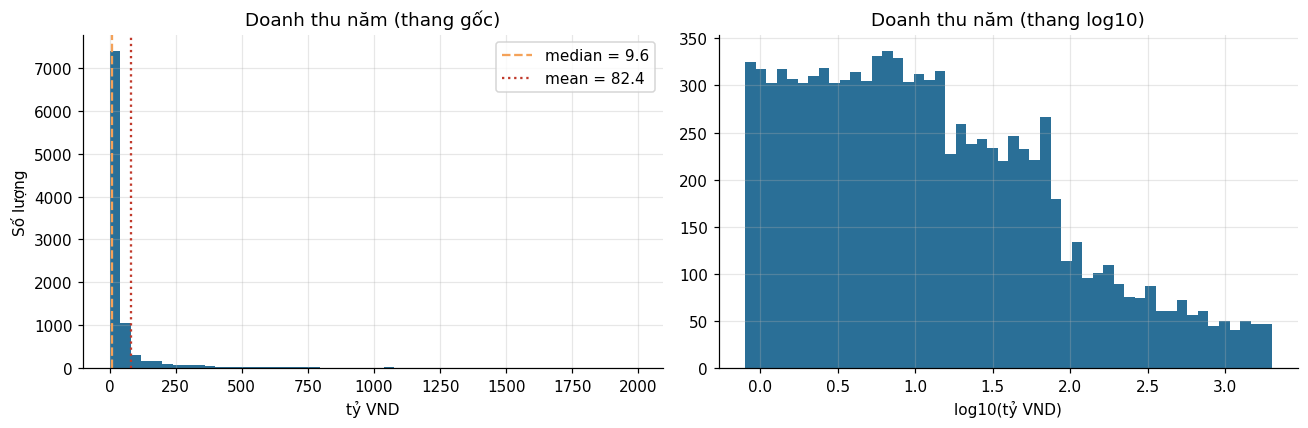

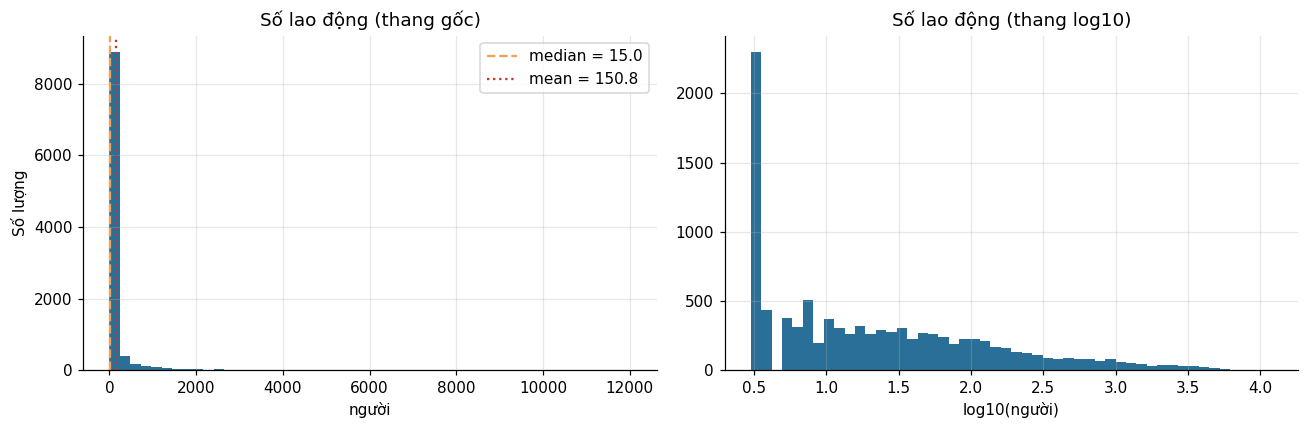


--- 05b_KH_doanhthu_theo_PK ---


,count,mean,std,min,5%,50%,95%,max,revenue_min_bn_vnd,revenue_max_bn_vnd
segment,,,,,,,,,,
MICRO,"5,900.00",4.88,3.86,0.80,0.92,3.52,13.05,14.99,0,15
SMALL,"2,560.00",39.01,18.58,15.01,16.39,34.51,73.83,79.97,15,80
MEDIUM 1,660.00,129.78,35.02,80.11,83.60,121.79,192.52,199.39,80,200
MEDIUM 2,335.00,288.84,56.91,200.56,207.93,285.40,389.01,399.36,200,400
UPPER 1,275.00,574.15,113.44,401.96,414.84,553.82,773.18,799.91,400,800
UPPER 2,115.00,985.33,106.81,803.29,820.67,989.46,"1,154.48","1,189.96",800,1200
BIGCORP 1,155.00,"1,562.28",226.62,"1,203.82","1,224.00","1,523.91","1,952.00","1,991.80",1200,2000


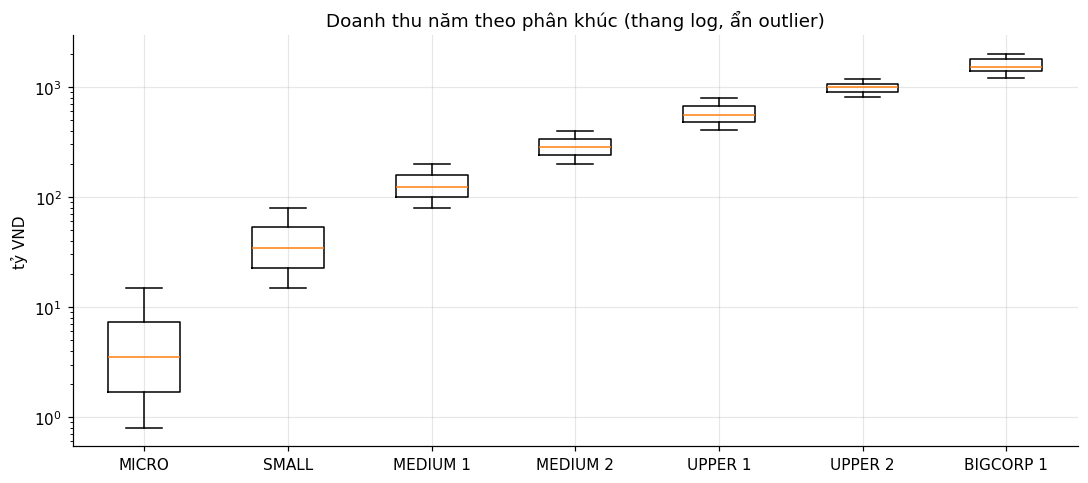


--- 05c_KH_segment ---


,số lượng,% số lượng
segment,,
MICRO,5900,59.00
SMALL,2560,25.60
MEDIUM 1,660,6.60
MEDIUM 2,335,3.35
UPPER 1,275,2.75
UPPER 2,115,1.15
BIGCORP 1,155,1.55


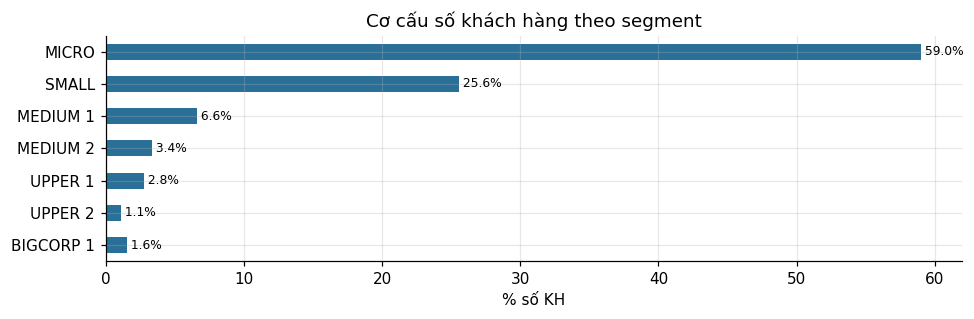

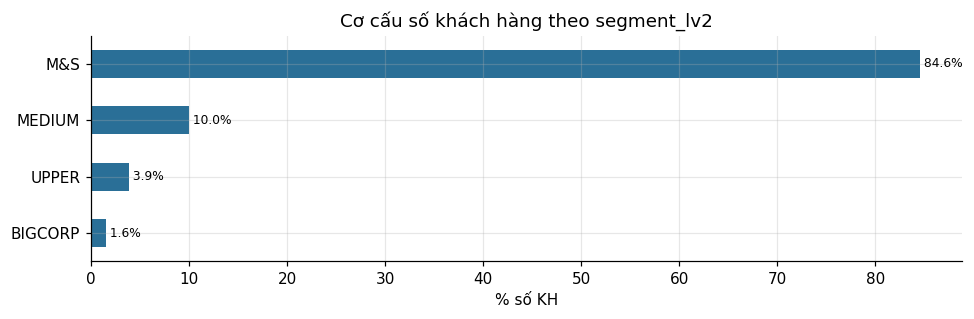


--- 05c_KH_industry_group ---


,số lượng,% số lượng
industry_group,,
Công nghiệp & Xây dựng,3070,30.70
Thương mại & Dịch vụ,3007,30.07
Vận tải & Logistics,1363,13.63
Nông nghiệp & Thực phẩm,1241,12.41
Khác,983,9.83
Bất động sản,216,2.16
Năng lượng & Khai khoáng,120,1.20


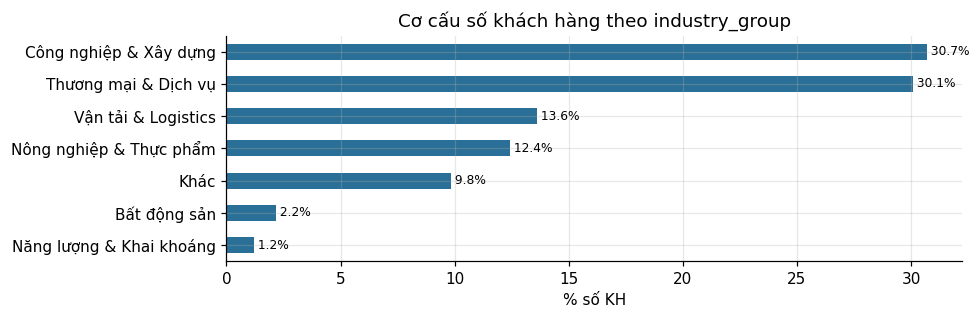

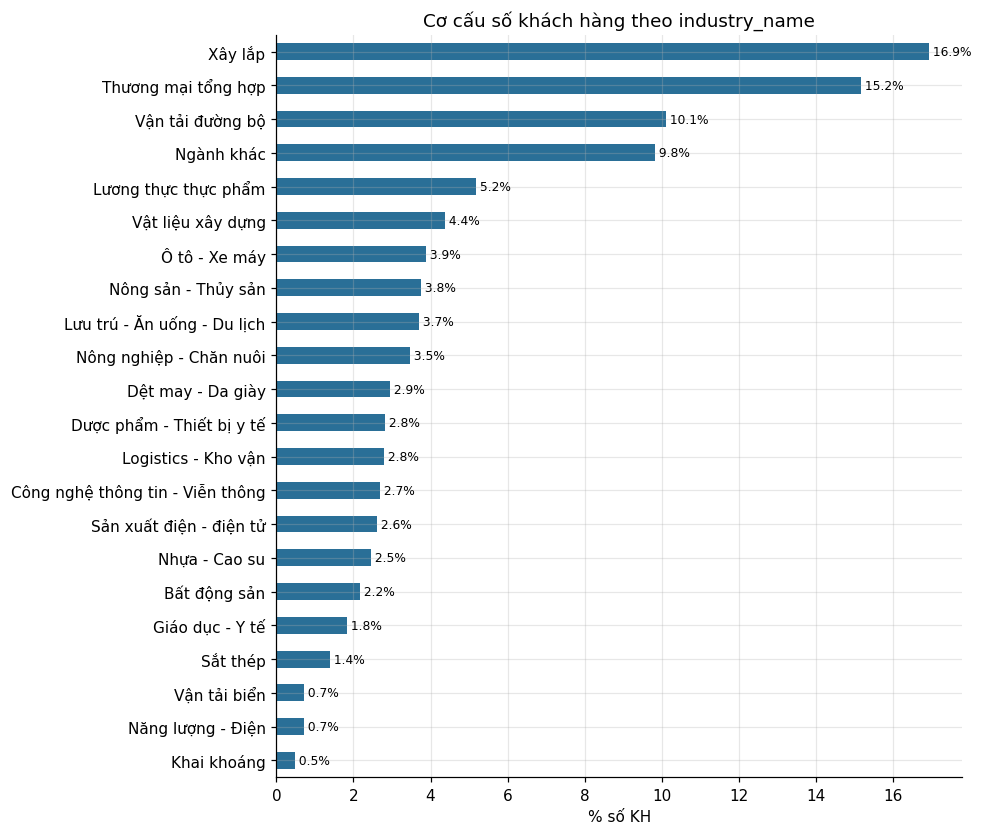

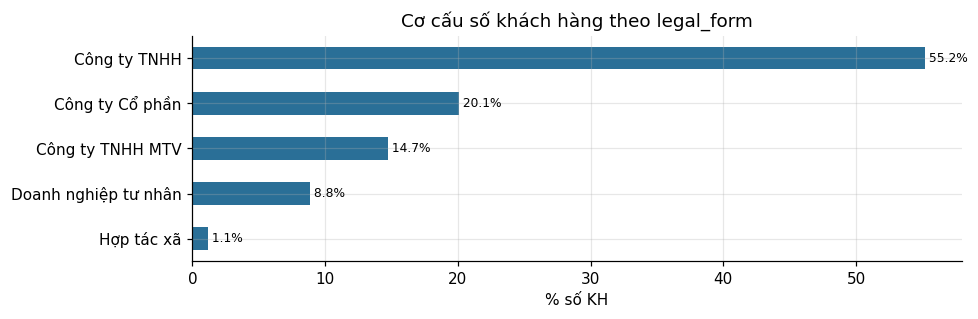

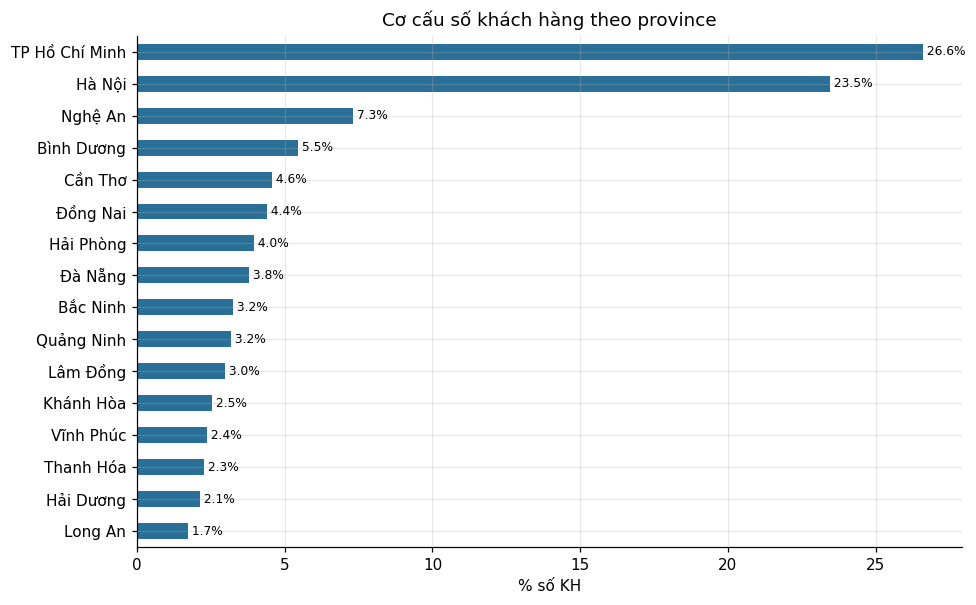

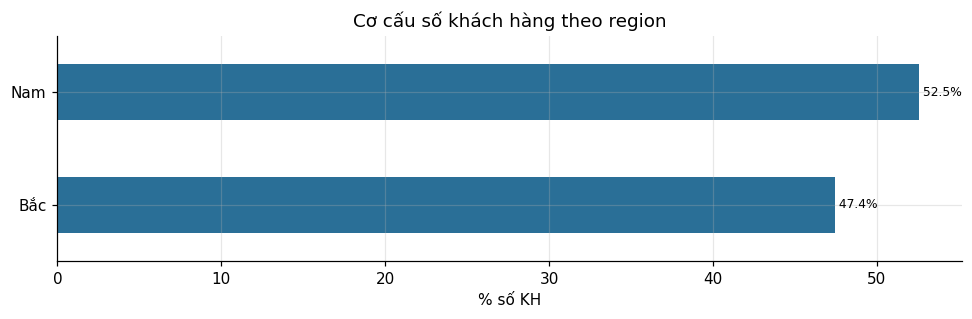


--- 05c_KH_credit_rating ---


,số lượng,% số lượng
credit_rating,,
AAA,12,0.12
AA,127,1.27
A,763,7.63
BBB,2719,27.19
BB,3400,34.00
B,2283,22.83
CCC,696,6.96


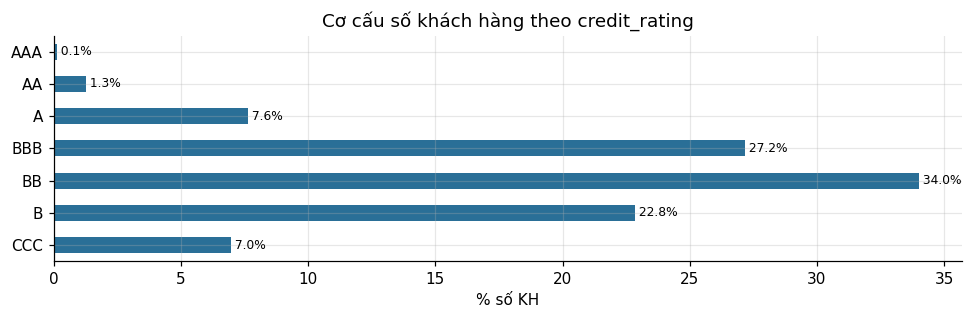

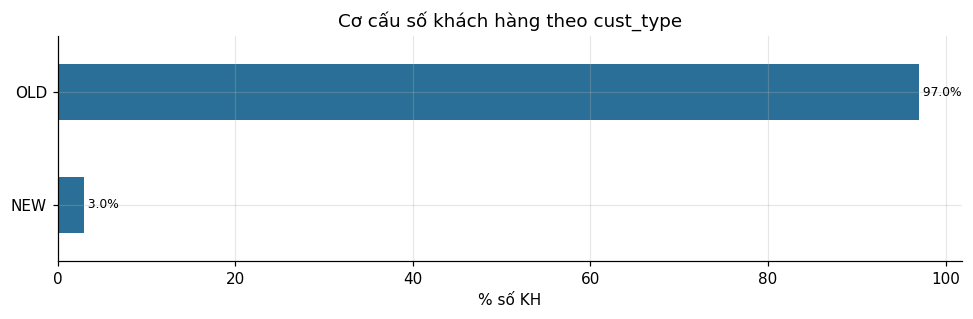

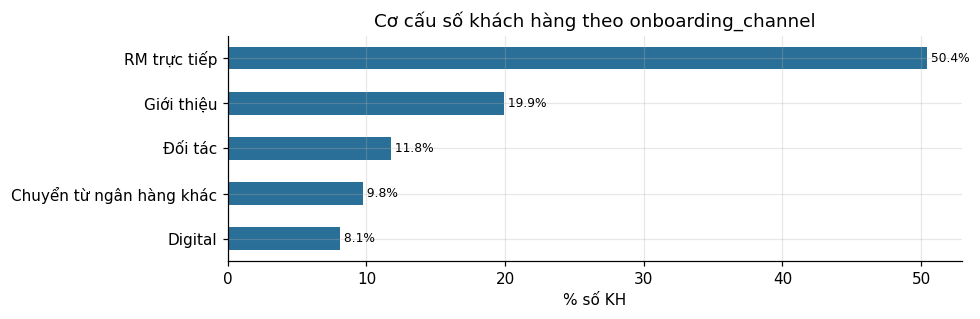


--- 05c_KH_customer_status ---


,số lượng,% số lượng
customer_status,,
Đang có dư nợ,8778,87.78
Không còn dư nợ,1222,12.22


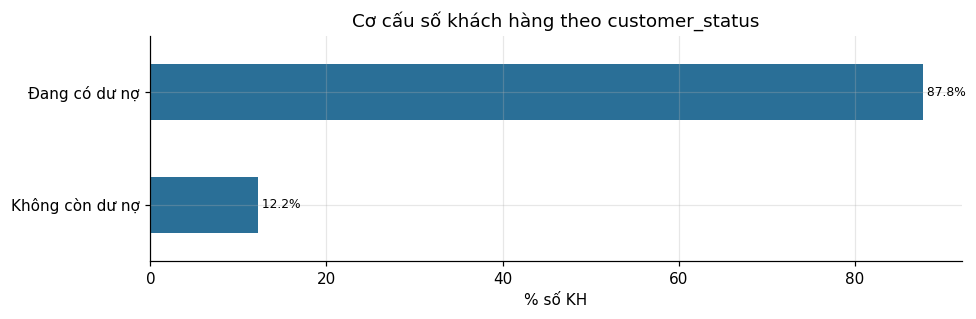

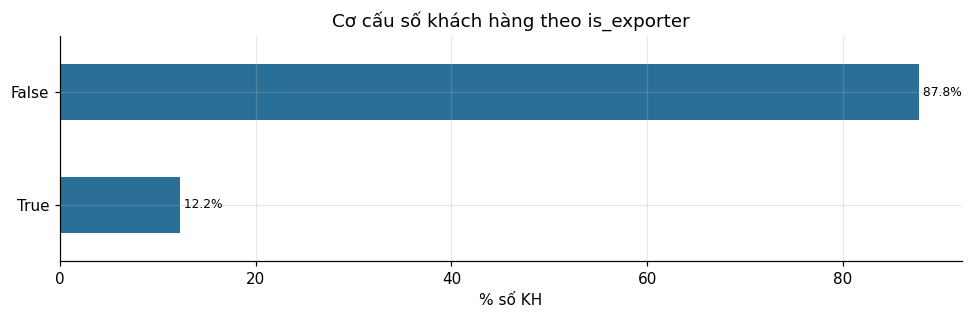

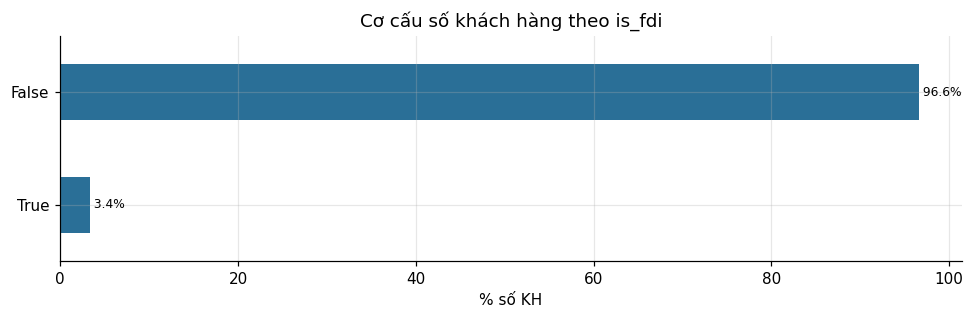


--- 05d_KH_PK_x_xephang ---


credit_rating,AAA,AA,A,BBB,BB,B,CCC
segment,,,,,,,
MICRO,0.00,0.92,6.39,24.92,35.27,24.75,7.76
SMALL,0.00,0.62,5.86,25.27,35.82,24.88,7.54
MEDIUM 1,0.00,1.97,11.82,38.03,29.09,15.76,3.33
MEDIUM 2,0.00,0.90,9.55,39.10,31.64,14.33,4.48
UPPER 1,0.36,5.09,18.18,44.36,23.27,6.55,2.18
UPPER 2,1.74,6.09,16.52,44.35,20.00,9.57,1.74
BIGCORP 1,5.81,12.90,36.77,30.32,10.97,3.23,0.00



--- 05e_KH_nganh_x_PK ---


segment,MICRO,SMALL,MEDIUM 1,MEDIUM 2,UPPER 1,UPPER 2,BIGCORP 1
industry_group,,,,,,,
Bất động sản,73,34,16,15,38,22,18
Công nghiệp & Xây dựng,1851,779,170,97,91,33,49
Khác,603,243,67,37,13,10,10
Nông nghiệp & Thực phẩm,702,338,106,49,24,9,13
Năng lượng & Khai khoáng,46,10,18,9,21,5,11
Thương mại & Dịch vụ,1792,823,216,80,52,17,27
Vận tải & Logistics,833,333,67,48,36,19,27


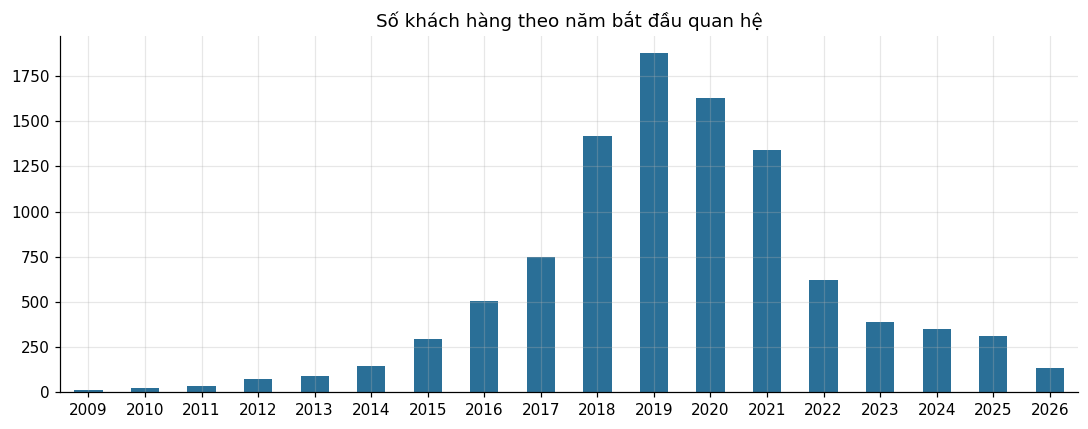

In [8]:
section("5. MÔ TẢ KHÁCH HÀNG")
cust_num_labels = {
    "revenue_bn": "Doanh thu năm (tỷ VND)", "employees": "Số lao động",
    "company_age": "Tuổi doanh nghiệp (năm)", "years_with_bank": "Số năm quan hệ với NH",
}
save_table("05a_KH_bien_so", describe_numeric(cust_x, list(cust_num_labels), cust_num_labels))

plot_hist_log(cust_x["revenue_bn"], "Doanh thu năm", "05_KH_doanh_thu", "tỷ VND")
plot_hist_log(cust_x["employees"], "Số lao động", "05_KH_so_lao_dong", "người")

# Doanh thu theo phân khúc - median & phân vị (kiểm tra phân khúc có khớp ngưỡng doanh thu không)
rev_by_seg = (cust_x.groupby("segment")["revenue_bn"]
              .describe(percentiles=[.05, .5, .95]).reindex(SEG_ORDER)
              .join(seg.set_index("segment")[["revenue_min_bn_vnd", "revenue_max_bn_vnd"]]))
save_table("05b_KH_doanhthu_theo_PK", rev_by_seg)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([cust_x.loc[cust_x["segment"] == s_, "revenue_bn"] for s_ in SEG_ORDER],
           tick_labels=SEG_ORDER, showfliers=False)
ax.set_yscale("log")
ax.set(title="Doanh thu năm theo phân khúc (thang log, ẩn outlier)", ylabel="tỷ VND")
save_chart(fig, "05_KH_doanhthu_boxplot_PK")

cust_cats = {
    "segment": SEG_ORDER, "segment_lv2": None, "industry_group": None, "industry_name": None,
    "legal_form": None, "province": None, "region": None, "credit_rating": RATING_ORDER,
    "cust_type": None, "onboarding_channel": None, "customer_status": None,
    "is_exporter": None, "is_fdi": None,
}
for c, order in cust_cats.items():
    t = freq_table(cust_x[c], order)
    save_table(f"05c_KH_{c}", t, show=c in ("segment", "industry_group", "credit_rating", "customer_status"))
    plot_bar(t["% số lượng"], f"Cơ cấu số khách hàng theo {c}", f"05_KH_{c}", "% số KH", pct=True)

# Bảng chéo hay dùng: phân khúc x xếp hạng tín dụng (% theo dòng)
ct = pd.crosstab(cust_x["segment"], cust_x["credit_rating"], normalize="index") * 100
save_table("05d_KH_PK_x_xephang", ct.reindex(index=SEG_ORDER, columns=RATING_ORDER))
ct2 = pd.crosstab(cust_x["industry_group"], cust_x["segment"]).reindex(columns=SEG_ORDER)
save_table("05e_KH_nganh_x_PK", ct2)

# Số KH mới theo năm bắt đầu quan hệ
new_by_year = cust_x["customer_since"].dt.year.value_counts().sort_index()
plot_bar(new_by_year, "Số khách hàng theo năm bắt đầu quan hệ", "05_KH_nam_bat_dau_QH",
         horizontal=False)

### 📝 Nhận xét - Khách hàng
**Có bao nhiêu khách hàng, là ai?**
- **10.000 KH doanh nghiệp**, trong đó 8.778 KH (87,8%) còn dư nợ tại 30/06/2026. Chỉ **300 KH (3%) là khách mới** (quan hệ dưới 12 tháng).
- **Phần lớn là doanh nghiệp nhỏ:** MICRO 59%, SMALL 25,6% → cứ 10 KH thì hơn 8 KH có doanh thu dưới 80 tỷ/năm. BIGCORP 1 chỉ có 155 KH (1,6%).
- **Loại hình:** Công ty TNHH chiếm hơn một nửa (55%), tiếp theo là Công ty Cổ phần (20%).
- **Ngành:** Công nghiệp & Xây dựng (31%) và Thương mại & Dịch vụ (30%) chiếm 61% số KH. Bất động sản chỉ 2,2%.
- **Địa bàn:** TP HCM (27%) và Hà Nội (23%) chiếm một nửa số KH; miền Nam 53%, miền Bắc 47%.
- **Xếp hạng tín dụng:** tập trung ở mức trung bình BBB–BB (61%). Hạng tốt (AAA–A) chỉ 9%, hạng yếu (B–CCC) tới 30%.
- **Đặc điểm khác:** 12% có xuất nhập khẩu, 3,4% là doanh nghiệp FDI; một nửa KH đến từ **RM trực tiếp** (50%), kênh Digital chỉ 8%.

**Doanh thu và quy mô:**
- Doanh thu năm **chênh lệch rất lớn**: một nửa KH có doanh thu dưới **9,6 tỷ**, nhưng trung bình lên tới **82 tỷ** do một số ít KH rất lớn (cao nhất gần 2.000 tỷ).
- Phân khúc khớp với ngưỡng doanh thu (ví dụ MICRO < 15 tỷ, BIGCORP 1 từ 1.200 tỷ).
- KH càng lớn thì xếp hạng càng tốt: 55% KH BIGCORP 1 có hạng A trở lên, trong khi MICRO chỉ khoảng 7%.

→ Biến tiền tệ lệch mạnh, nên dùng **median** và **biểu đồ thang log** khi mô tả.

## 6. MÔ TẢ HỢP ĐỒNG VAY (dim_loan_contract)


6. MÔ TẢ HỢP ĐỒNG VAY

--- 06a_HD_bien_so ---


,n,mean,median,std,min,P1,P5,P25,P75,P95,P99,max,IQR,CV (std/mean),skewness,kurtosis,% bằng 0,số outlier (1.5 IQR)
biến,,,,,,,,,,,,,,,,,,
Giải ngân (tỷ VND),31104,12.97,4.39,41.84,0.04,0.26,0.58,1.86,10.99,46.29,136.45,"2,148.55",9.13,3.22,20.88,720.59,0.00,3469
Hạn mức (tỷ VND),31104,14.57,4.93,46.33,0.05,0.29,0.64,2.10,12.41,52.04,152.98,"2,167.28",10.31,3.18,19.46,612.89,0.00,3434
Kỳ hạn (tháng),31104,24.01,12.00,27.41,3.00,3.00,3.00,6.00,36.00,84.00,120.00,120.00,30.00,1.14,1.80,3.02,0.00,2005
Lãi suất (%/năm),31104,10.51,10.73,2.34,4.28,4.64,5.27,9.24,12.24,13.88,14.32,15.06,3.00,0.22,-0.69,0.23,0.00,412
FTP (%/năm),31104,7.92,7.48,1.58,3.98,4.02,4.23,7.30,8.84,10.29,10.38,10.40,1.54,0.20,-0.66,0.57,0.00,2779
Chênh lệch LS - FTP (điểm %),31104,2.59,2.70,1.06,0.30,0.30,0.76,1.72,3.53,4.03,4.30,4.95,1.81,0.41,-0.31,-1.01,0.00,0
Giá trị TSBĐ (tỷ VND),31104,16.65,5.47,59.38,0.00,0.00,0.00,1.93,14.29,58.79,171.50,"4,053.87",12.35,3.57,27.43,"1,286.81",10.34,3422
LTV (%),27887,64.89,65.00,11.57,45.00,45.00,47.00,55.00,75.00,83.00,85.00,85.00,20.00,0.18,0.01,-1.21,0.00,0



Số hợp đồng trên mỗi KH:
count   10,000.00
mean         3.11
std          3.15
min          1.00
25%          1.00
50%          2.00
75%          4.00
max         35.00

--- 06b_HD_term_group ---


,số lượng,% số lượng
term_group,,
ST,18478,59.41
MLT,12349,39.70
Thấu chi,277,0.89



--- 06b_HD_contract_status ---


,số lượng,% số lượng
contract_status,,
Đã tất toán,19738,63.46
Đang hiệu lực,11073,35.60
Đã xóa nợ,293,0.94



--- 06b_HD_collateral_type ---


,số lượng,% số lượng
collateral_type,,
Bất động sản,15489,49.80
Hàng tồn kho/Phải thu,5425,17.44
Động sản/Phương tiện vận tải,4105,13.20
Tín chấp,3217,10.34
Tiền gửi/Giấy tờ có giá,2868,9.22



--- 06c_HD_laisuat_kyhan_tien ---


median       count       
ccy           USD   VND   USD    VND
term_group                          
MLT          6.96 12.59   134  12215
ST           5.19  9.82  2350  16128
Thấu chi     6.35 11.03     5    272

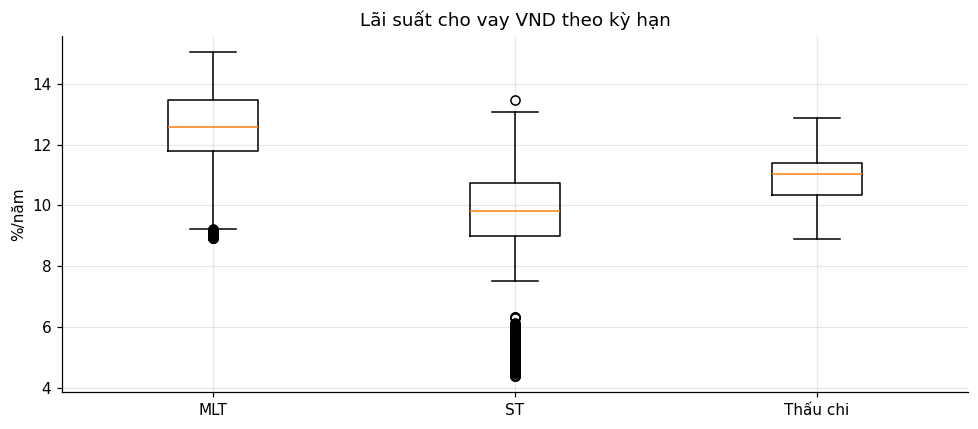

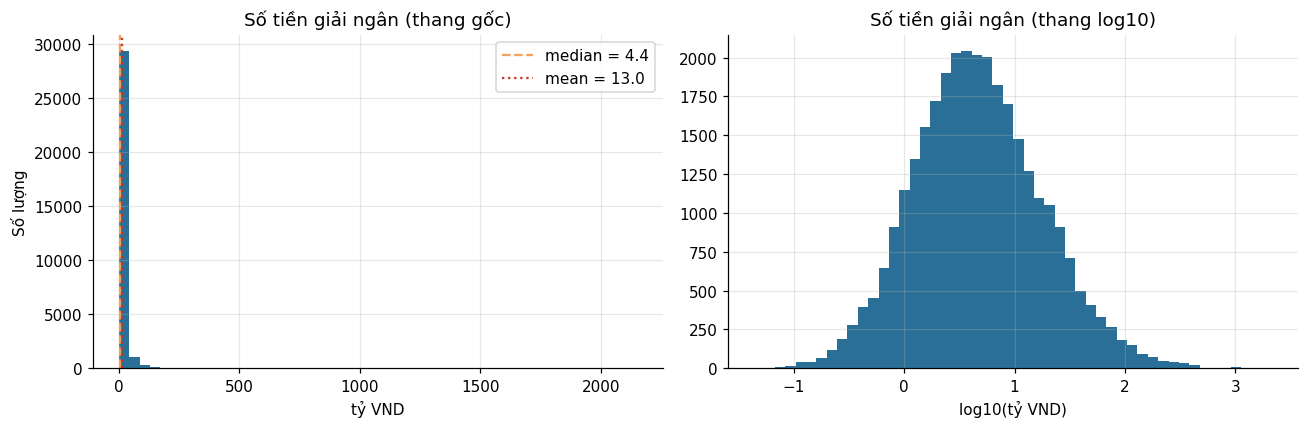

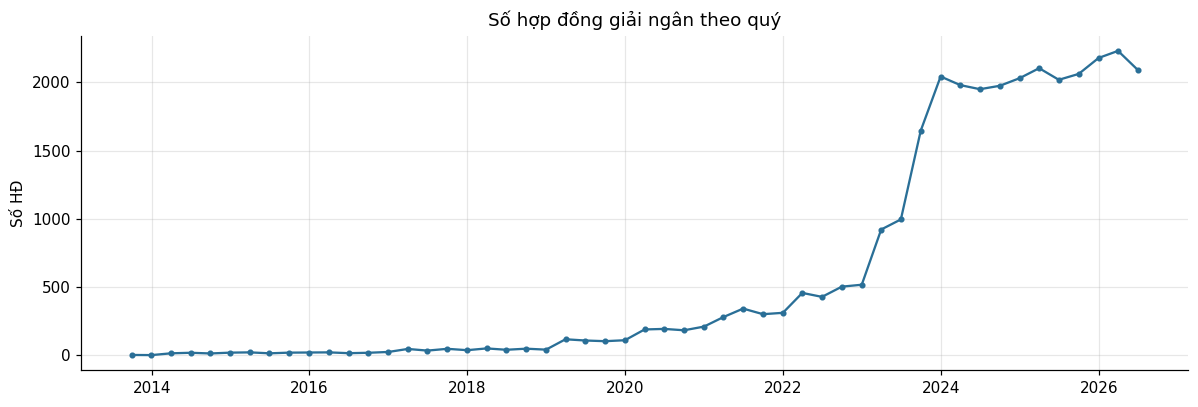

In [9]:
section("6. MÔ TẢ HỢP ĐỒNG VAY")
loan_x["disbursed_bn"] = loan_x["disbursed_amount_vnd"] / TY
loan_x["limit_bn"] = loan_x["credit_limit_vnd"] / TY
loan_x["collateral_bn"] = loan_x["collateral_value_vnd"] / TY
loan_x["spread_pct"] = loan_x["interest_rate_pct"] - loan_x["ftp_rate_pct"]
loan_num_labels = {
    "disbursed_bn": "Giải ngân (tỷ VND)", "limit_bn": "Hạn mức (tỷ VND)",
    "tenor_months": "Kỳ hạn (tháng)", "interest_rate_pct": "Lãi suất (%/năm)",
    "ftp_rate_pct": "FTP (%/năm)", "spread_pct": "Chênh lệch LS - FTP (điểm %)",
    "collateral_bn": "Giá trị TSBĐ (tỷ VND)", "ltv_pct": "LTV (%)",
}
save_table("06a_HD_bien_so", describe_numeric(loan_x, list(loan_num_labels), loan_num_labels))
print("\nSố hợp đồng trên mỗi KH:")
print(loan_x.groupby("cif").size().describe().to_string())

loan_cats = ["term_group", "ccy", "product_code", "product_lv2", "contract_status", "exit_reason",
             "loan_purpose", "repayment_method", "collateral_type", "is_secured",
             "origination_channel", "restructured_flag", "campaign_category"]
for c in loan_cats:
    t = freq_table(loan_x[c].fillna("(còn hiệu lực)") if c == "exit_reason" else loan_x[c])
    save_table(f"06b_HD_{c}", t, show=c in ("term_group", "contract_status", "collateral_type"))

# Lãi suất theo kỳ hạn x loại tiền (median)
rate_tbl = loan_x.pivot_table(index="term_group", columns="ccy", values="interest_rate_pct",
                              aggfunc=["median", "count"])
save_table("06c_HD_laisuat_kyhan_tien", rate_tbl)

fig, ax = plt.subplots(figsize=(9, 4))
groups = sorted(loan_x["term_group"].unique())
ax.boxplot([loan_x.loc[(loan_x["term_group"] == g) & (loan_x["ccy"] == "VND"), "interest_rate_pct"]
            for g in groups], tick_labels=groups)
ax.set(title="Lãi suất cho vay VND theo kỳ hạn", ylabel="%/năm")
save_chart(fig, "06_HD_laisuat_kyhan")

plot_hist_log(loan_x["disbursed_bn"], "Số tiền giải ngân", "06_HD_giai_ngan", "tỷ VND")

# Số hợp đồng giải ngân theo tháng
disb_m = loan_x.set_index("open_date").resample("QE")["contract_id"].count()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(disb_m.index, disb_m.values, color=C_MAIN, marker="o", ms=3)
ax.set(title="Số hợp đồng giải ngân theo quý", ylabel="Số HĐ")
save_chart(fig, "06_HD_giai_ngan_theo_quy")

### 📝 Nhận xét - Hợp đồng vay
- **31.104 hợp đồng**, trung bình mỗi KH có **3 hợp đồng** (nhiều nhất 35). Hiện **11.073 hợp đồng (35,6%) còn hiệu lực**, phần lớn hợp đồng đã kết thúc là do **tái tục** sang hợp đồng mới (59%); chỉ 0,9% bị xóa nợ.
- **Kỳ hạn:** ngắn hạn chiếm 59% số hợp đồng, trung dài hạn 40%, thấu chi gần như không đáng kể (0,9%).
- **Loại tiền & sản phẩm:** 92% hợp đồng bằng VND; 94% là cho vay thường, LC UPAS chỉ khoảng 6%.
- **Mục đích vay:** hơn một nửa để **bổ sung vốn lưu động** (54%), tiếp theo là đầu tư TSCĐ (17,5%).
- **Tài sản bảo đảm:** 90% hợp đồng có TSBĐ, chủ yếu là **bất động sản** (50%); 10% là tín chấp. LTV phổ biến 55–75%.
- **Số tiền giải ngân:** một nửa hợp đồng dưới **4,4 tỷ**, trung bình 13 tỷ, lớn nhất hơn 2.100 tỷ.
- **Lãi suất:** trung bình **10,5%/năm**; trung dài hạn (~12,6%) cao hơn ngắn hạn (~9,8%); vay USD thấp hơn hẳn VND (5–7%). Chênh lệch giữa lãi suất và chi phí vốn FTP khoảng **2,6 điểm %**.
- 1/3 hợp đồng được hưởng chương trình ưu đãi lãi suất; 1,1% hợp đồng đã cơ cấu nợ.

## 7. DƯ NỢ TẠI NGÀY CHỐT MỚI NHẤT: QUY MÔ & CƠ CẤU


7. DƯ NỢ TẠI 30/06/2026: QUY MÔ & CƠ CẤU

--- 07a_KPI_ngay_chot ---


,giá trị
Tổng dư nợ (tỷ),"98,367.30"
Số hợp đồng có dư nợ,"11,073.00"
Số KH có dư nợ,"8,778.00"
Dư nợ BQ / KH (tỷ),11.21
Dư nợ median / KH (tỷ),2.79
Tỷ lệ OD2 (%),0.94
Tỷ lệ OD3-5 / nợ xấu (%),2.63
Gốc quá hạn (tỷ),"2,058.95"
Dự phòng (tỷ),"2,340.49"
Hạn mức chưa giải ngân (tỷ),"3,866.25"



--- 07b_dunoKH_phan_phoi ---


,n,mean,median,std,min,P1,P5,P25,P75,P95,P99,max,IQR,CV (std/mean),skewness,kurtosis,% bằng 0,số outlier (1.5 IQR)
biến,,,,,,,,,,,,,,,,,,
Dư nợ / KH (tỷ),8778,11.21,2.79,45.87,0.00,0.03,0.16,0.94,7.72,40.47,141.96,"2,171.59",6.78,4.09,21.23,731.22,0.00,1067


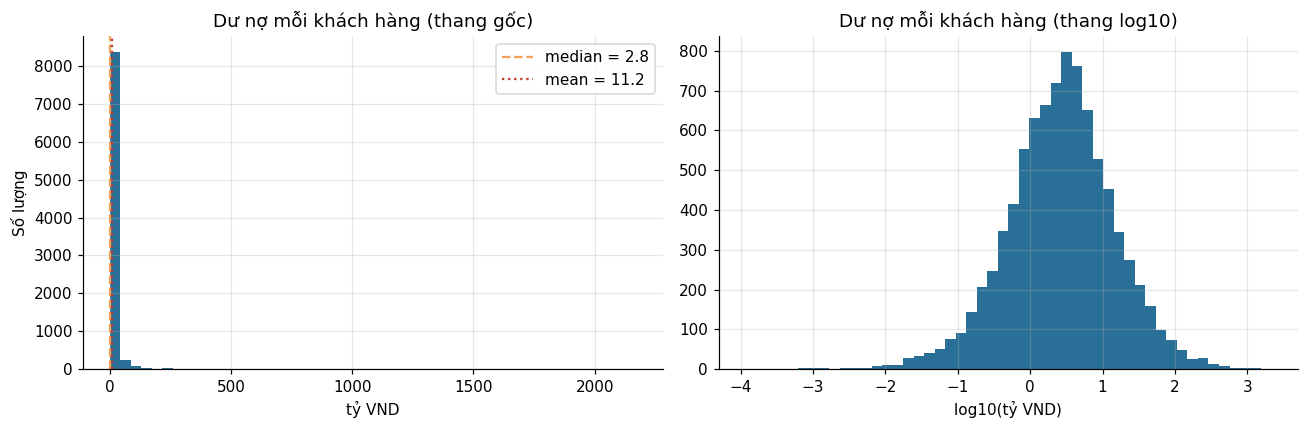


--- 07c_coCau_segment ---


,so_KH,so_HD,% số KH,dư nợ (tỷ),% dư nợ,dư nợ BQ/KH (tỷ),tỷ lệ nợ xấu (%)
segment,,,,,,,
MICRO,5084,5817,57.92,"19,874.13",20.20,3.91,3.07
SMALL,2246,2750,25.59,"14,000.00",14.23,6.23,3.96
MEDIUM 1,601,881,6.85,"10,475.52",10.65,17.43,2.69
MEDIUM 2,314,502,3.58,"10,671.33",10.85,33.99,3.10
UPPER 1,266,512,3.03,"15,468.53",15.73,58.15,1.25
UPPER 2,114,236,1.30,"6,853.15",6.97,60.12,2.78
BIGCORP 1,153,375,1.74,"21,024.65",21.37,137.42,2.01


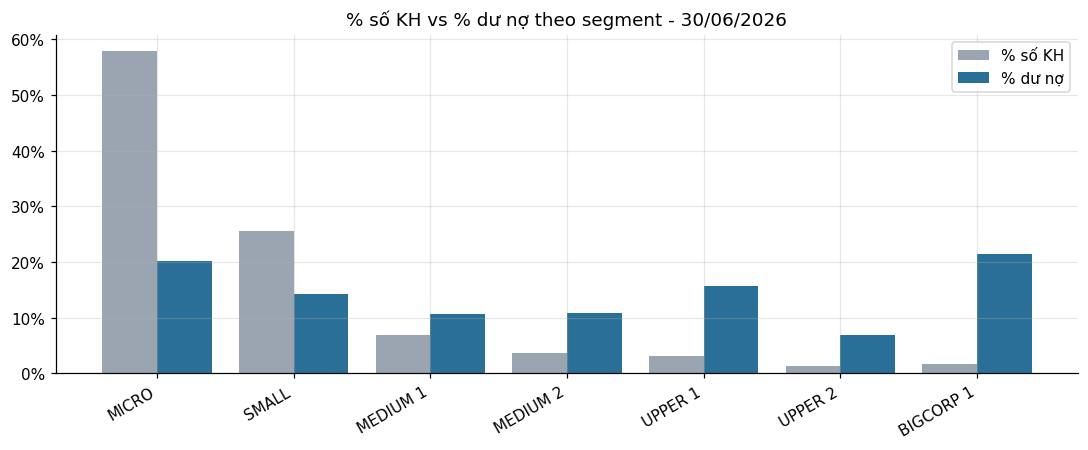


--- 07c_coCau_industry_group ---


,so_KH,so_HD,% số KH,dư nợ (tỷ),% dư nợ,dư nợ BQ/KH (tỷ),tỷ lệ nợ xấu (%)
industry_group,,,,,,,
Công nghiệp & Xây dựng,2658,3355,30.28,"29,458.37",29.95,11.08,3.27
Thương mại & Dịch vụ,2648,3307,30.17,"22,785.92",23.16,8.60,2.73
Vận tải & Logistics,1180,1468,13.44,"12,964.48",13.18,10.99,1.48
Nông nghiệp & Thực phẩm,1098,1382,12.51,"12,564.49",12.77,11.44,1.41
Khác,885,1087,10.08,"9,738.74",9.90,11.00,1.10
Bất động sản,201,308,2.29,"8,459.17",8.60,42.09,6.15
Năng lượng & Khai khoáng,108,166,1.23,"2,396.14",2.44,22.19,0.12


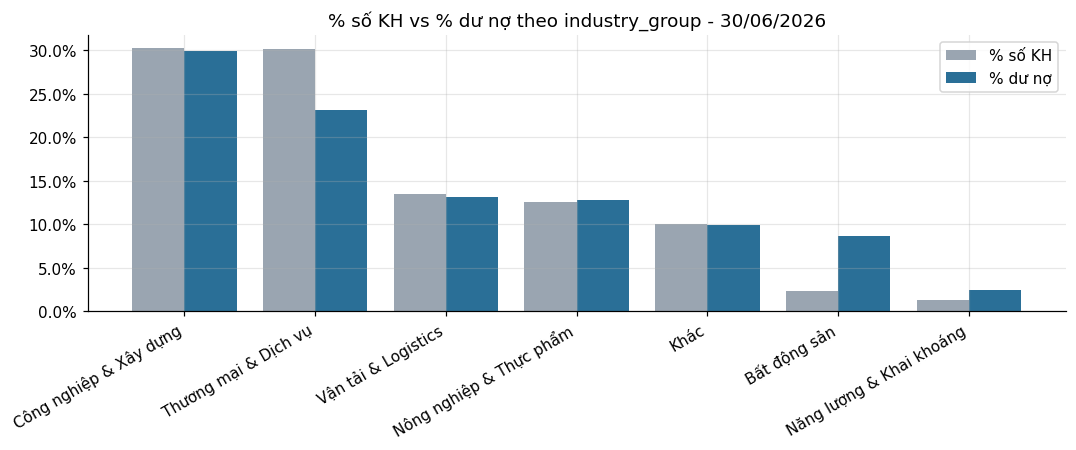

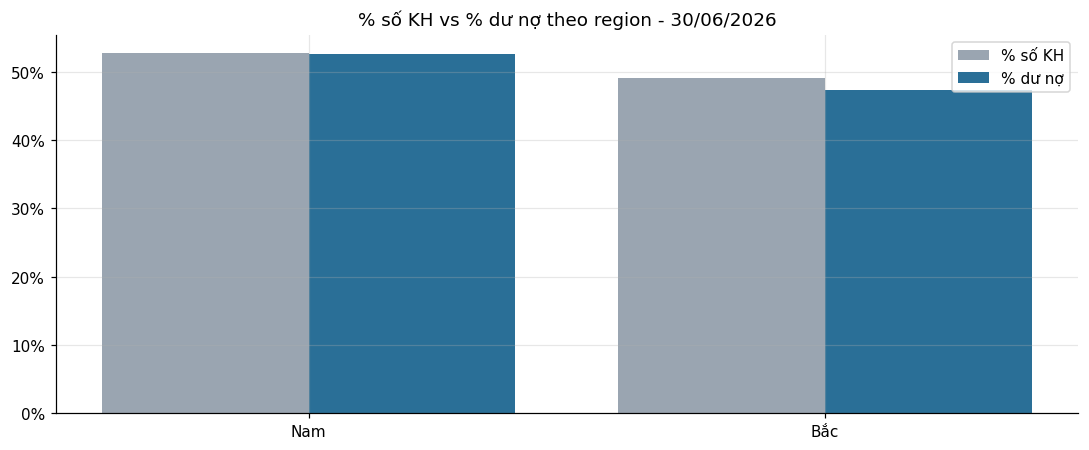


--- 07c_coCau_term_group ---


,so_KH,so_HD,% số KH,dư nợ (tỷ),% dư nợ,dư nợ BQ/KH (tỷ),tỷ lệ nợ xấu (%)
term_group,,,,,,,
ST,3027,3620,34.48,"62,850.96",63.89,20.76,1.92
MLT,6506,7368,74.12,"34,050.69",34.62,5.23,4.06
Thấu chi,84,85,0.96,"1,465.66",1.49,17.45,0.00


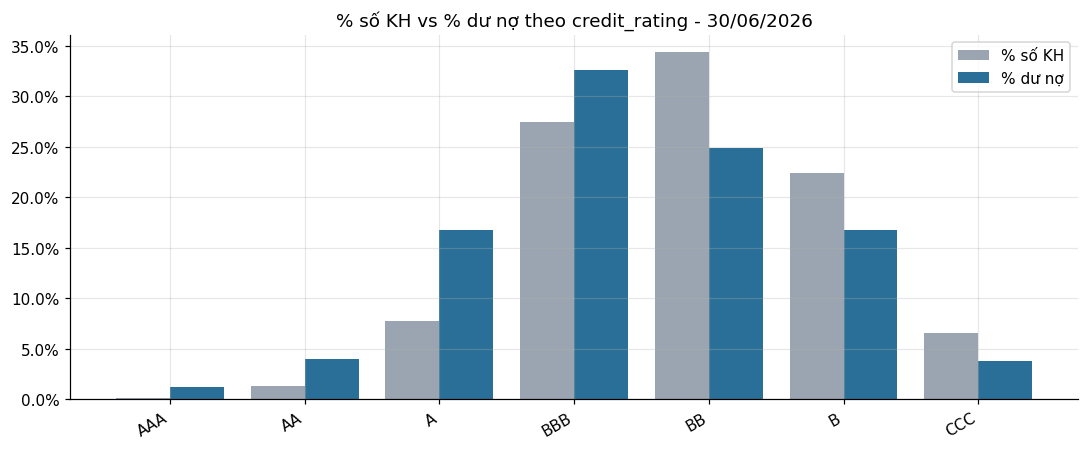


--- 07c_coCau_debt_group_code ---


,so_KH,so_HD,% số KH,dư nợ (tỷ),% dư nợ,dư nợ BQ/KH (tỷ)
debt_group_code,,,,,,
NORM,8443,10596,96.18,"94,853.27",96.43,11.23
OD5,187,187,2.13,"1,132.85",1.15,6.06
OD2,142,143,1.62,927.53,0.94,6.53
OD3,68,69,0.77,923.22,0.94,13.58
OD4,78,78,0.89,530.43,0.54,6.80


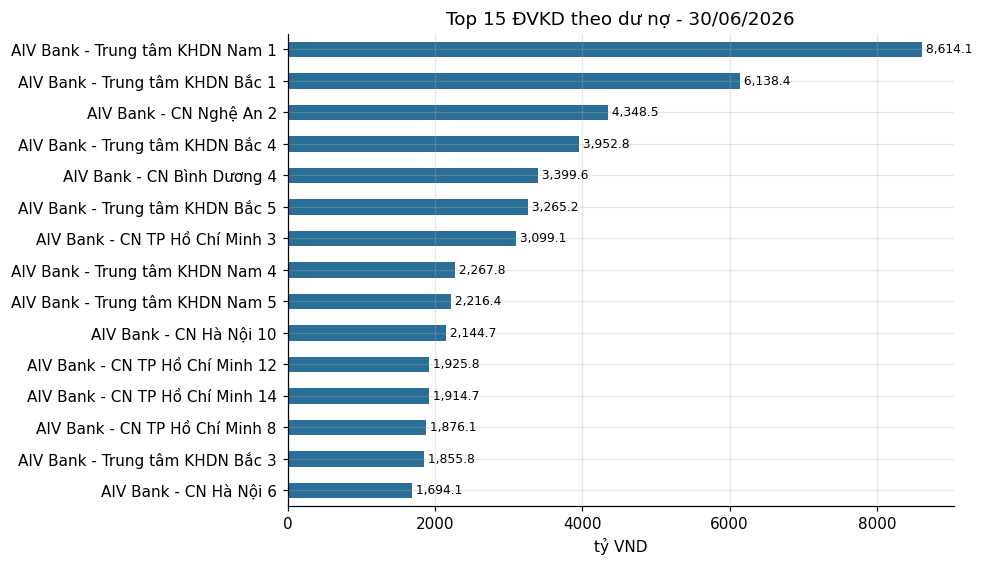

In [10]:
section(f"7. DƯ NỢ TẠI {SNAP_DATE:%d/%m/%Y}: QUY MÔ & CƠ CẤU")
total_now = bal_now["balance_vnd"].sum()
kpi = pd.Series({
    "Tổng dư nợ (tỷ)": total_now / TY,
    "Số hợp đồng có dư nợ": bal_now["contract_id"].nunique(),
    "Số KH có dư nợ": bal_now["cif"].nunique(),
    "Dư nợ BQ / KH (tỷ)": total_now / TY / bal_now["cif"].nunique(),
    "Dư nợ median / KH (tỷ)": bal_now.groupby("cif")["balance_vnd"].sum().median() / TY,
    "Tỷ lệ OD2 (%)": bal_now.loc[bal_now["is_od2"], "balance_vnd"].sum() / total_now * 100,
    "Tỷ lệ OD3-5 / nợ xấu (%)": bal_now.loc[bal_now["is_od35"], "balance_vnd"].sum() / total_now * 100,
    "Gốc quá hạn (tỷ)": bal_now["principal_overdue_vnd"].sum() / TY,
    "Dự phòng (tỷ)": bal_now["provision_vnd"].sum() / TY,
    "Hạn mức chưa giải ngân (tỷ)": bal_now["undrawn_limit_vnd"].sum() / TY,
}).rename("giá trị").to_frame()
save_table("07a_KPI_ngay_chot", kpi)

# Phân phối dư nợ cấp khách hàng
cust_bal_now = bal_now.groupby("cif")["balance_vnd"].sum().rename("balance_vnd").to_frame()
cust_bal_now["balance_bn"] = cust_bal_now["balance_vnd"] / TY
save_table("07b_dunoKH_phan_phoi",
           describe_numeric(cust_bal_now, ["balance_bn"], {"balance_bn": "Dư nợ / KH (tỷ)"}))
plot_hist_log(cust_bal_now["balance_bn"], "Dư nợ mỗi khách hàng", "07_duno_moi_KH", "tỷ VND")

# Cơ cấu: so sánh % số KH với % dư nợ (thường rất khác nhau)
dims = {"segment": SEG_ORDER, "segment_lv2": None, "industry_group": None, "industry_name": None,
        "region": None, "term_group": None, "ccy": None, "product_code": None,
        "collateral_type": None, "credit_rating": RATING_ORDER, "debt_group_code": None}
for d, order in dims.items():
    g = bal_now.groupby(d).agg(so_KH=("cif", "nunique"), so_HD=("contract_id", "nunique"),
                               du_no=("balance_vnd", "sum"))
    g["% số KH"] = g["so_KH"] / bal_now["cif"].nunique() * 100
    g["dư nợ (tỷ)"] = g["du_no"] / TY
    g["% dư nợ"] = g["du_no"] / total_now * 100
    g["dư nợ BQ/KH (tỷ)"] = g["dư nợ (tỷ)"] / g["so_KH"]
    if d not in ("debt_group_code",):
        od35 = bal_now[bal_now["is_od35"]].groupby(d)["balance_vnd"].sum()
        g["tỷ lệ nợ xấu (%)"] = (od35 / g["du_no"] * 100).fillna(0)
    g = g.drop(columns="du_no")
    g = g.reindex(order) if order else g.sort_values("% dư nợ", ascending=False)
    save_table(f"07c_coCau_{d}", g, show=d in ("segment", "industry_group", "term_group", "debt_group_code"))

    if d in ("segment", "industry_group", "credit_rating", "region"):
        fig, ax = plt.subplots(figsize=(10, 4.2))
        x = np.arange(len(g))
        ax.bar(x - 0.2, g["% số KH"], 0.4, label="% số KH", color=C_GREY)
        ax.bar(x + 0.2, g["% dư nợ"], 0.4, label="% dư nợ", color=C_MAIN)
        ax.set_xticks(x, g.index, rotation=30 if len(g) > 5 else 0, ha="right" if len(g) > 5 else "center")
        ax.yaxis.set_major_formatter(mtick.PercentFormatter())
        ax.set(title=f"% số KH vs % dư nợ theo {d} - {SNAP_DATE:%d/%m/%Y}")
        ax.legend()
        save_chart(fig, f"07_coCau_{d}")

# Dư nợ theo ĐVKD (top 15)
br = (bal_now.groupby("branch_name")["balance_vnd"].sum() / TY).sort_values(ascending=False)
plot_bar(br.head(15), f"Top 15 ĐVKD theo dư nợ - {SNAP_DATE:%d/%m/%Y}", "07_top15_DVKD", "tỷ VND")
save_table("07d_duno_theo_DVKD", br.rename("dư nợ (tỷ)").to_frame(), show=False)

### 📝 Nhận xét - Dư nợ tại 30/06/2026
**Bức tranh chung:** tổng dư nợ **98.367 tỷ**, của 8.778 KH và 11.073 hợp đồng. Nợ nhóm 2 là 0,94%, nợ xấu 2,63%. Ngân hàng đã trích dự phòng 2.340 tỷ, lớn hơn số gốc quá hạn 2.059 tỷ.

**Khách nhỏ đông, khách lớn nhiều tiền** (so sánh % số KH với % dư nợ):

| Nhóm | % số KH | % dư nợ | Dư nợ BQ/KH |
|---|---|---|---|
| MICRO + SMALL | 83,5% | 34,4% | 4–6 tỷ |
| MEDIUM 1 + 2 | 10,4% | 21,5% | 17–34 tỷ |
| UPPER 1 + 2 + BIGCORP 1 | 6,1% | 44,1% | 58–137 tỷ |

- **Ngành:** Công nghiệp & Xây dựng (30%) và Thương mại & Dịch vụ (23%) chiếm hơn một nửa dư nợ. **Bất động sản** chỉ có 2,3% số KH nhưng chiếm 8,6% dư nợ, mỗi KH vay trung bình 42 tỷ.
- **Kỳ hạn:** ngắn hạn chiếm 64% dư nợ; số KH có khoản trung dài hạn đông hơn (74%) nhưng khoản vay nhỏ hơn.
- **Loại tiền:** USD chiếm 15% dư nợ nhưng chỉ khoảng 4% số KH → khách vay USD là khách lớn.
- **Nợ xấu khác nhau giữa các nhóm:**
  - Bất động sản **6,2%**, Sản xuất điện - điện tử **9,2%**, cao hơn hẳn mức chung 2,6%.
  - Trung dài hạn **4,1%**, gấp đôi ngắn hạn (1,9%).
  - Xếp hạng càng thấp, nợ xấu càng cao: A 0,4% → BBB 2,8% → B 4,9% → CCC 8,1%.

→ Khi mô tả cơ cấu, luôn đặt **% số KH** cạnh **% dư nợ**, vì hai con số này rất khác nhau.

## 8. MỨC ĐỘ TẬP TRUNG


8. MỨC ĐỘ TẬP TRUNG DƯ NỢ

--- 08a_tap_trung ---


,số lượng,top 1 (%),top 10 (%),top 20 (%),top 1% số lượng (%),top 10% số lượng (%),HHI (0-10000),Gini
đối tượng,,,,,,,,
Khách hàng,8778,2.21,9.82,14.21,29.38,67.72,20.23,0.77
ĐVKD,78,8.76,40.10,57.40,8.76,33.36,267.84,0.45
Ngành,22,13.16,71.68,97.56,13.16,23.52,680.19,0.37



--- 08b_top20_KH ---


,balance_bn,customer_name,segment,industry_name,credit_rating,% dư nợ,% lũy kế
cif,,,,,,,
AIV1004748,"2,171.59",Công ty TNHH Xây dựng Vexada,BIGCORP 1,Xây lắp,B,2.21,2.21
AIV1006304,"1,165.07",Công ty Cổ phần Đầu tư Wijogor,BIGCORP 1,Ngành khác,BBB,1.18,3.39
AIV1004870,"1,130.52",Công ty Cổ phần Địa ốc Triorfa,BIGCORP 1,Bất động sản,A,1.15,4.54
AIV1006129,"1,015.78",Công ty Cổ phần Địa ốc Lomjovor,BIGCORP 1,Bất động sản,A,1.03,5.57
AIV1003515,"1,002.37",Công ty TNHH Nông thủy sản Datrixa,BIGCORP 1,Nông sản - Thủy sản,AA,1.02,6.59
AIV1008712,754.24,Công ty TNHH Địa ốc Kaxaze,UPPER 1,Bất động sản,B,0.77,7.36
AIV1002600,724.30,Công ty TNHH Nông nghiệp Bramirnox,BIGCORP 1,Nông nghiệp - Chăn nuôi,BBB,0.74,8.10
AIV1009751,589.72,Công ty TNHH Kim loại Hilomvor,UPPER 1,Sắt thép,BBB,0.60,8.70
AIV1009723,555.32,Công ty Cổ phần Địa ốc Pakatun,UPPER 1,Bất động sản,A,0.56,9.26


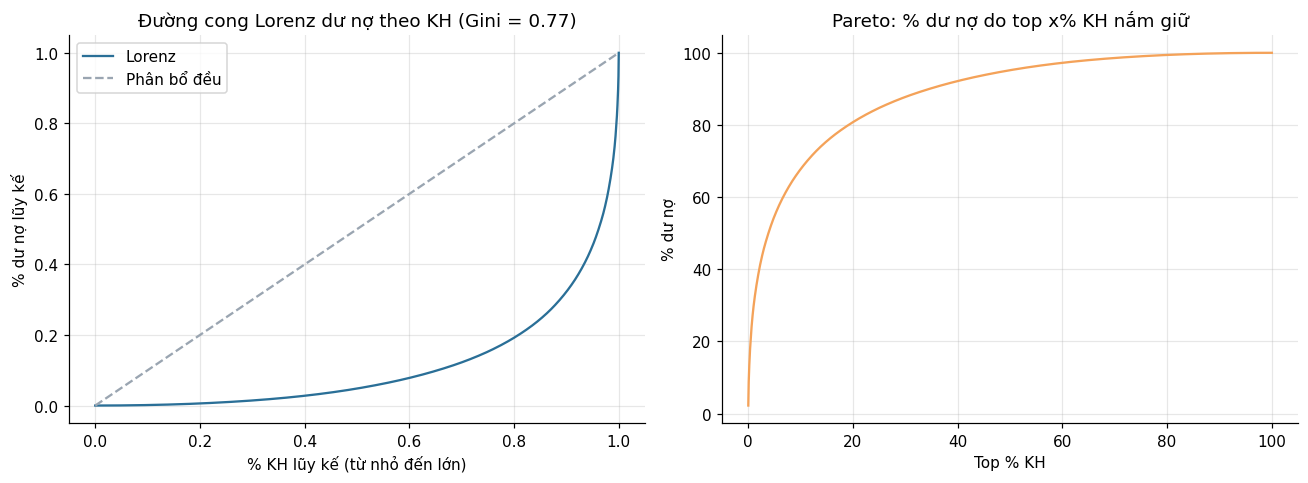

In [11]:
section("8. MỨC ĐỘ TẬP TRUNG DƯ NỢ")


def concentration(values, label):
    v = np.sort(np.asarray(values, dtype=float))[::-1]
    share = v / v.sum()
    n = len(v)
    lorenz = np.cumsum(np.sort(v)) / v.sum()
    gini = 1 - 2 * np.trapezoid(np.insert(lorenz, 0, 0), dx=1 / n)
    return {
        "đối tượng": label, "số lượng": n,
        "top 1 (%)": share[:1].sum() * 100, "top 10 (%)": share[:10].sum() * 100,
        "top 20 (%)": share[:20].sum() * 100,
        "top 1% số lượng (%)": share[:max(1, n // 100)].sum() * 100,
        "top 10% số lượng (%)": share[:max(1, n // 10)].sum() * 100,
        "HHI (0-10000)": (share ** 2).sum() * 10000, "Gini": gini,
    }


conc = pd.DataFrame([
    concentration(cust_bal_now["balance_vnd"], "Khách hàng"),
    concentration(bal_now.groupby("branch_name")["balance_vnd"].sum(), "ĐVKD"),
    concentration(bal_now.groupby("industry_name")["balance_vnd"].sum(), "Ngành"),
]).set_index("đối tượng")
save_table("08a_tap_trung", conc)

top20 = (cust_bal_now.join(cust_x.set_index("cif")[["customer_name", "segment", "industry_name",
                                                     "credit_rating"]])
         .sort_values("balance_vnd", ascending=False).head(20))
top20["% dư nợ"] = top20["balance_vnd"] / total_now * 100
top20["% lũy kế"] = top20["% dư nợ"].cumsum()
save_table("08b_top20_KH", top20.drop(columns="balance_vnd"))

# Đường cong Lorenz & Pareto theo khách hàng
v = np.sort(cust_bal_now["balance_vnd"].values)
lor = np.insert(np.cumsum(v) / v.sum(), 0, 0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(np.linspace(0, 1, len(lor)), lor, color=C_MAIN, label="Lorenz")
ax[0].plot([0, 1], [0, 1], color=C_GREY, ls="--", label="Phân bổ đều")
ax[0].set(title=f"Đường cong Lorenz dư nợ theo KH (Gini = {conc.loc['Khách hàng', 'Gini']:.2f})",
          xlabel="% KH lũy kế (từ nhỏ đến lớn)", ylabel="% dư nợ lũy kế")
ax[0].legend()
desc = np.cumsum(v[::-1]) / v.sum() * 100
ax[1].plot(np.arange(1, len(desc) + 1) / len(desc) * 100, desc, color=C_ACCENT)
ax[1].set(title="Pareto: % dư nợ do top x% KH nắm giữ", xlabel="Top % KH", ylabel="% dư nợ")
save_chart(fig, "08_lorenz_pareto_KH")

### 📝 Nhận xét - Mức độ tập trung
- Dư nợ **tập trung rất cao vào một nhóm nhỏ KH**:
  - 10% KH lớn nhất (khoảng 880 KH) nắm **68%** dư nợ; 1% KH lớn nhất (88 KH) nắm **29%**.
  - Top 10 KH chiếm **9,8%**, KH lớn nhất chiếm **2,2%** tổng dư nợ.
  - Hệ số Gini = **0,77** (0 là chia đều, 1 là dồn hết vào một KH) → mức tập trung cao.
- Theo ĐVKD: top 10 trong 78 ĐVKD chiếm **40%** dư nợ.
- Theo ngành: 22 ngành nhưng chỉ vài ngành đã chiếm phần lớn; ngành lớn nhất chiếm 13%.

→ Các chỉ số trung bình dễ bị một vài KH lớn kéo lệch. Kết quả phân tích phía sau nên được kiểm tra lại khi loại các KH lớn nhất ra.

## 9. XU HƯỚNG THEO THỜI GIAN


9. XU HƯỚNG THEO THỜI GIAN

--- 09a_xu_huong_du_no ---


,so_HD,so_KH,dư nợ (tỷ),MoM (%),YoY (%),tỷ lệ OD2 (%),tỷ lệ OD3-5 (%)
snapshot_date,,,,,,,
2023-12-31,10481,9180,"69,478.39",NaN,NaN,0.95,1.65
2024-01-31,10520,9178,"70,438.87",1.38,NaN,0.88,1.83
2024-02-29,10539,9156,"71,158.71",1.02,NaN,0.82,1.94
2024-03-31,10560,9147,"71,956.09",1.12,NaN,0.86,1.94
2024-04-30,10575,9128,"73,785.94",2.54,NaN,0.81,2.11
2024-05-31,10598,9113,"74,759.19",1.32,NaN,0.57,2.25
2024-06-30,10609,9097,"75,194.00",0.58,NaN,0.83,2.24
2024-07-31,10614,9070,"76,094.36",1.20,NaN,1.14,2.24
2024-08-31,10614,9049,"77,057.44",1.27,NaN,1.02,2.31


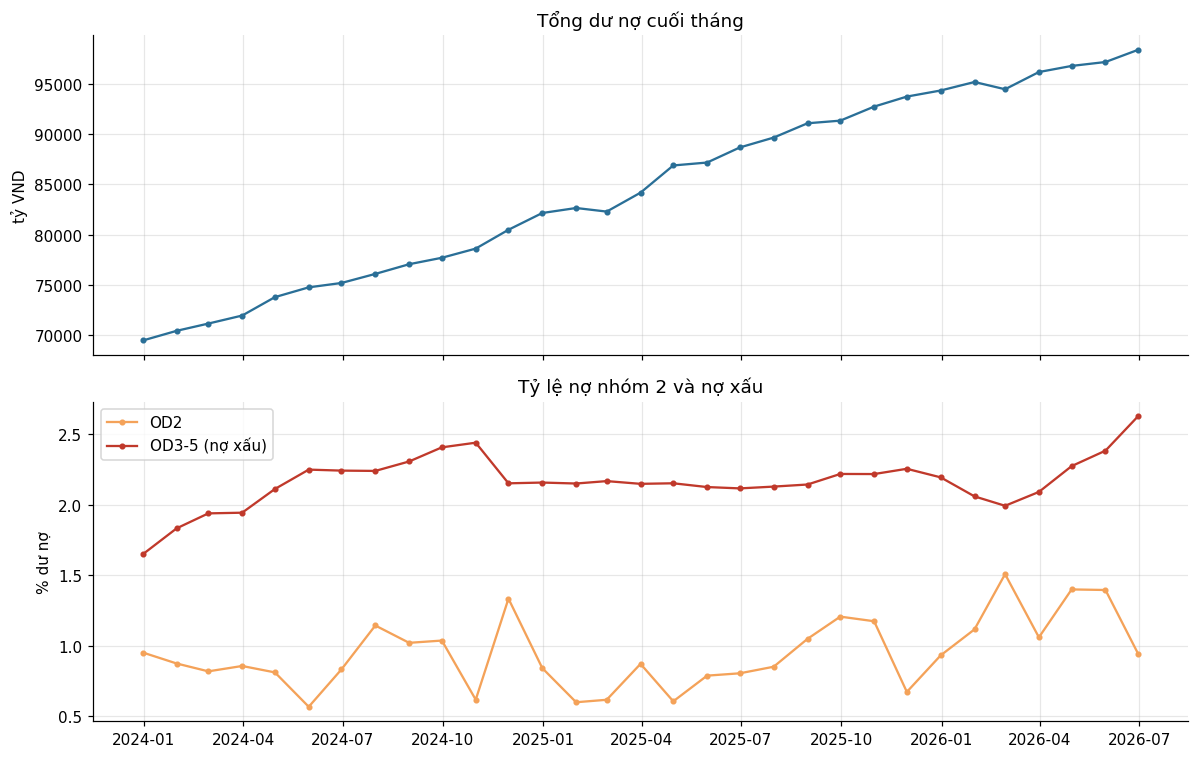

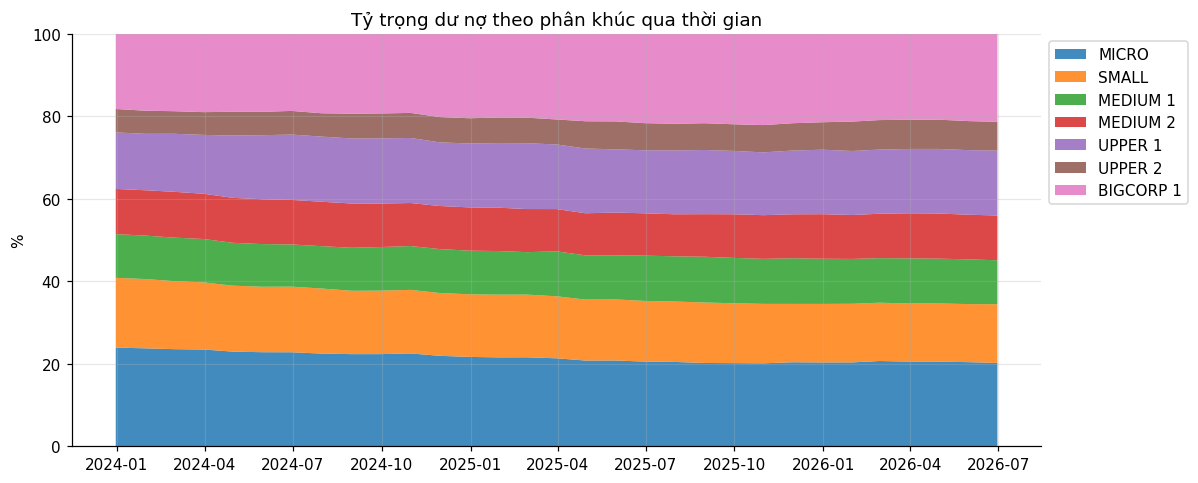


--- 09c_thu_nhap_theo_thang ---


,NII (tỷ),NFI (tỷ),TOI (tỷ),NIM quy năm (%),NFI/TOI (%)
period_end_date,,,,,
2024-01-31,114.37,43.38,157.76,1.92,27.50
2024-02-29,114.75,48.34,163.09,2.04,29.64
2024-03-31,115.51,42.55,158.05,1.90,26.92
2024-04-30,116.06,48.01,164.06,1.94,29.26
2024-05-31,117.11,45.12,162.23,1.86,27.81
2024-06-30,117.83,46.42,164.25,1.91,28.26
2024-07-31,118.07,46.36,164.43,1.84,28.20
2024-08-31,117.61,47.21,164.82,1.81,28.64
2024-09-30,117.25,43.81,161.07,1.84,27.20



--- 09d_thu_nhap_YTD ---


,NII YTD T1-T6 (tỷ),NFI YTD (tỷ),TOI YTD (tỷ)
year,,,
2024,695.63,273.81,969.44
2025,780.88,321.46,"1,102.35"
2026,802.50,362.97,"1,165.48"


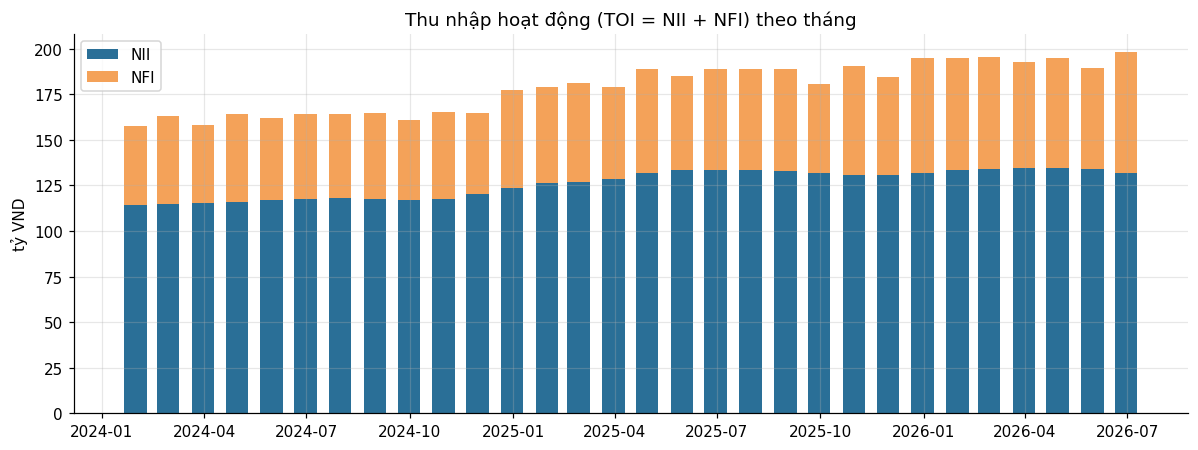


--- 09e_mua_vu_MoM_theo_thang ---


,MoM trung bình (%)
thang,
1,0.96
2,-0.06
3,1.74
4,2.13
5,0.68
6,1.18
7,1.15
8,1.43
9,0.56


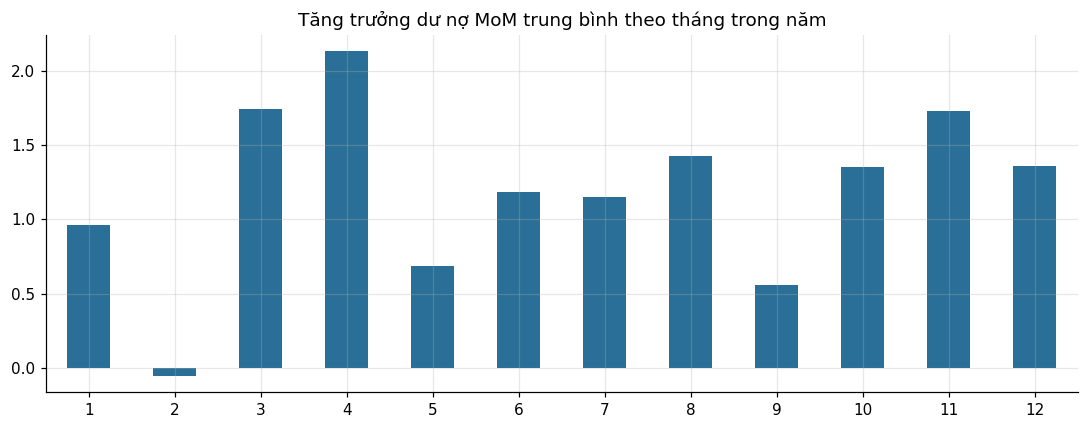

In [12]:
section("9. XU HƯỚNG THEO THỜI GIAN")
# Dư nợ: mỗi tháng lấy số dư tại ngày chốt của tháng đó (không cộng dồn qua tháng)
trend = bal_x.groupby("snapshot_date").agg(
    du_no=("balance_vnd", "sum"), so_HD=("contract_id", "nunique"), so_KH=("cif", "nunique"))
trend["od2"] = bal_x[bal_x["is_od2"]].groupby("snapshot_date")["balance_vnd"].sum()
trend["od35"] = bal_x[bal_x["is_od35"]].groupby("snapshot_date")["balance_vnd"].sum()
trend = trend.fillna(0)
trend["dư nợ (tỷ)"] = trend["du_no"] / TY
trend["MoM (%)"] = trend["du_no"].pct_change() * 100
trend["YoY (%)"] = trend["du_no"].pct_change(12) * 100
trend["tỷ lệ OD2 (%)"] = trend["od2"] / trend["du_no"] * 100
trend["tỷ lệ OD3-5 (%)"] = trend["od35"] / trend["du_no"] * 100
trend = trend.drop(columns=["du_no", "od2", "od35"])
save_table("09a_xu_huong_du_no", trend)

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
ax[0].plot(trend.index, trend["dư nợ (tỷ)"], color=C_MAIN, marker="o", ms=3)
ax[0].set(title="Tổng dư nợ cuối tháng", ylabel="tỷ VND")
ax[1].plot(trend.index, trend["tỷ lệ OD2 (%)"], color=C_ACCENT, marker="o", ms=3, label="OD2")
ax[1].plot(trend.index, trend["tỷ lệ OD3-5 (%)"], color=C_RED, marker="o", ms=3, label="OD3-5 (nợ xấu)")
ax[1].set(title="Tỷ lệ nợ nhóm 2 và nợ xấu", ylabel="% dư nợ")
ax[1].legend()
save_chart(fig, "09_xu_huong_du_no_no_xau")

# Cơ cấu dư nợ theo phân khúc qua thời gian (stacked area, % tỷ trọng)
seg_trend = bal_x.pivot_table(index="snapshot_date", columns="segment", values="balance_vnd",
                              aggfunc="sum")[SEG_ORDER]
seg_share = seg_trend.div(seg_trend.sum(axis=1), axis=0) * 100
save_table("09b_tytrong_PK_theo_thang", seg_share, show=False)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.stackplot(seg_share.index, seg_share.T.values, labels=SEG_ORDER, alpha=0.85)
ax.set(title="Tỷ trọng dư nợ theo phân khúc qua thời gian", ylabel="%", ylim=(0, 100))
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
save_chart(fig, "09_tytrong_PK_theo_thang")

# Thu nhập: chỉ tiêu PHÁT SINH -> cộng theo tháng / năm
inc_m = inc.groupby("period_end_date")[["avg_balance_vnd", "interest_income_vnd", "funding_cost_vnd",
                                        "nii_mtd", "nfi_mtd", "toi_mtd"]].sum()
days = inc.groupby("period_end_date")["days_in_month"].first()
inc_m["NIM quy năm (%)"] = inc_m["nii_mtd"] / inc_m["avg_balance_vnd"] * 365 / days * 100
inc_m["NFI/TOI (%)"] = inc_m["nfi_mtd"] / inc_m["toi_mtd"] * 100
inc_tbl = inc_m[["nii_mtd", "nfi_mtd", "toi_mtd"]] / TY
inc_tbl.columns = ["NII (tỷ)", "NFI (tỷ)", "TOI (tỷ)"]
inc_tbl = inc_tbl.join(inc_m[["NIM quy năm (%)", "NFI/TOI (%)"]])
save_table("09c_thu_nhap_theo_thang", inc_tbl)

inc_y = inc.assign(year=inc["period_end_date"].dt.year, month=inc["period_end_date"].dt.month)
ytd = (inc_y[inc_y["month"] <= SNAP_DATE.month].groupby("year")[["nii_mtd", "nfi_mtd", "toi_mtd"]]
       .sum() / TY)
ytd.columns = [f"NII YTD T1-T{SNAP_DATE.month} (tỷ)", "NFI YTD (tỷ)", "TOI YTD (tỷ)"]
save_table("09d_thu_nhap_YTD", ytd)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(inc_tbl.index, inc_tbl["NII (tỷ)"], width=20, color=C_MAIN, label="NII")
ax.bar(inc_tbl.index, inc_tbl["NFI (tỷ)"], width=20, bottom=inc_tbl["NII (tỷ)"], color=C_ACCENT, label="NFI")
ax.set(title="Thu nhập hoạt động (TOI = NII + NFI) theo tháng", ylabel="tỷ VND")
ax.legend()
save_chart(fig, "09_thu_nhap_theo_thang")

# Mùa vụ: dư nợ trung bình theo tháng trong năm (đã loại bỏ xu hướng bằng MoM)
season = trend.assign(thang=trend.index.month).groupby("thang")["MoM (%)"].mean()
save_table("09e_mua_vu_MoM_theo_thang", season.to_frame("MoM trung bình (%)"))
plot_bar(season, "Tăng trưởng dư nợ MoM trung bình theo tháng trong năm", "09_mua_vu_MoM",
         horizontal=False)

### 📝 Nhận xét - Xu hướng theo thời gian
**Dư nợ:**
- Tăng gần như liên tục từ **69.478 tỷ (12/2023)** lên **98.367 tỷ (06/2026)**, tức +41% sau 30 tháng.
- Tốc độ tăng so với cùng kỳ (YoY) **đang chậm lại**: khoảng 17–18% trong năm 2025, còn khoảng 11% giữa năm 2026.
- Trong khi đó **số KH có dư nợ giảm nhẹ** (9.180 → 8.778) → mỗi KH vay nhiều hơn.
- **Mùa vụ:** dư nợ thường giảm vào **tháng 2** (dịp Tết) ở cả 2025 và 2026.
- **Cơ cấu dịch chuyển dần sang khách lớn:** tỷ trọng dư nợ của MICRO + SMALL giảm từ 40,8% (12/2023) xuống 34,4% (06/2026), còn UPPER + BIGCORP tăng từ 37,7% lên 44,1%.

**Chất lượng nợ:**
- Nợ xấu tăng từ 1,65% (12/2023) lên khoảng 2,2% rồi **giữ ổn định suốt năm 2025**.
- Từ 02/2026 nợ xấu **tăng 4 tháng liên tục**, từ 1,99% lên **2,63%**.
- Nợ nhóm 2 lên xuống thất thường giữa các tháng (0,6–1,5%).

**Thu nhập:**
- TOI tăng từ khoảng 158 tỷ/tháng (01/2024) lên 195–198 tỷ/tháng (2026). Lũy kế 6 tháng đầu năm: 969 → 1.102 → **1.165 tỷ**.
- NII **gần như đi ngang** trong năm 2026 (khoảng 132–135 tỷ/tháng) dù dư nợ vẫn tăng → biên lãi NIM giảm dần (khoảng 1,9% → 1,7%).
- Thu phí (NFI) chiếm khoảng 30% TOI và thường tăng vọt vào **tháng cuối quý, cuối năm**.

## 10. MỐI QUAN HỆ CƠ BẢN GIỮA CÁC BIẾN


10. MỐI QUAN HỆ CƠ BẢN

--- 10a_tuong_quan_spearman ---


,revenue_bn,employees,company_age,years_with_bank,balance_bn,so_HD,LS_BQ
revenue_bn,1.00,0.96,0.19,-0.05,0.38,0.27,-0.43
employees,0.96,1.00,0.19,-0.05,0.37,0.26,-0.42
company_age,0.19,0.19,1.00,0.43,0.06,0.11,-0.05
years_with_bank,-0.05,-0.05,0.43,1.00,-0.20,-0.00,0.26
balance_bn,0.38,0.37,0.06,-0.20,1.00,0.44,-0.50
so_HD,0.27,0.26,0.11,-0.00,0.44,1.00,-0.23
LS_BQ,-0.43,-0.42,-0.05,0.26,-0.50,-0.23,1.00


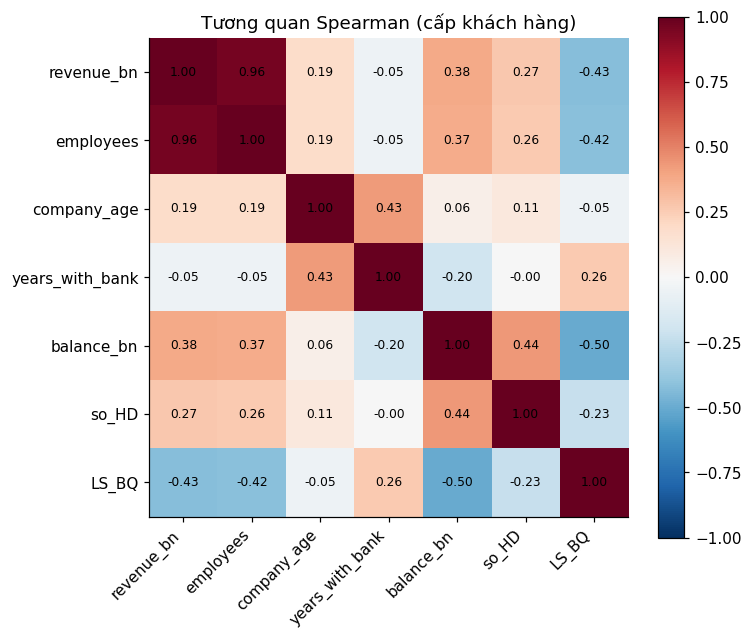

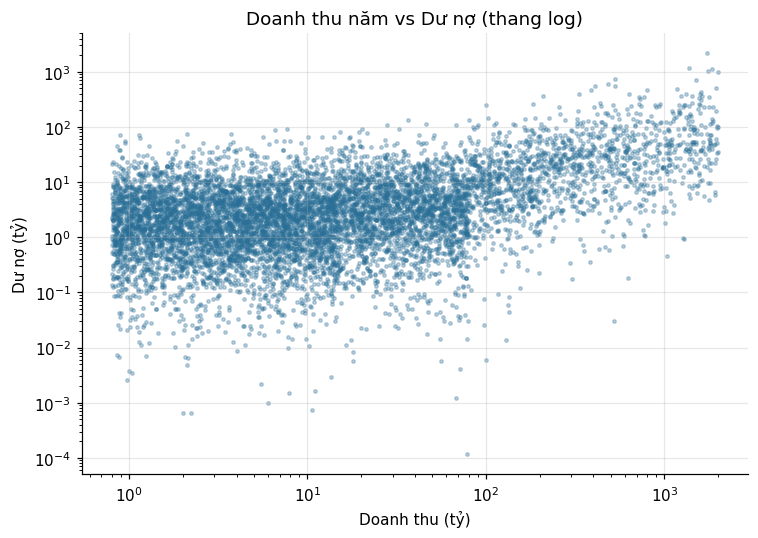


--- 10b_noxau_theo_xephang ---


,dư nợ (tỷ),tỷ lệ OD3-5 (%)
credit_rating,,
AAA,"1,190.42",0.00
AA,"3,965.62",0.00
A,"16,489.47",0.38
BBB,"32,076.19",2.76
BB,"24,444.98",2.16
B,"16,505.13",4.93
CCC,"3,695.49",8.09


In [13]:
section("10. MỐI QUAN HỆ CƠ BẢN")
cust_level = (cust_x.set_index("cif")[["revenue_bn", "employees", "company_age", "years_with_bank"]]
              .join(cust_bal_now["balance_bn"], how="inner"))
cust_level["so_HD"] = bal_now.groupby("cif")["contract_id"].nunique()
cust_level["LS_BQ"] = loan_x[loan_x["contract_status"] == "Đang hiệu lực"].groupby("cif")["interest_rate_pct"].mean()
# Spearman phù hợp hơn Pearson với biến tiền tệ lệch mạnh
corr = cust_level.corr(method="spearman")
save_table("10a_tuong_quan_spearman", corr)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im)
ax.set_title("Tương quan Spearman (cấp khách hàng)")
save_chart(fig, "10_tuong_quan")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(cust_level["revenue_bn"], cust_level["balance_bn"], s=5, alpha=0.3, color=C_MAIN)
ax.set(xscale="log", yscale="log", title="Doanh thu năm vs Dư nợ (thang log)",
       xlabel="Doanh thu (tỷ)", ylabel="Dư nợ (tỷ)")
save_chart(fig, "10_doanhthu_vs_duno")

# Tỷ lệ nợ xấu theo xếp hạng tín dụng (kiểm tra xếp hạng có phân biệt rủi ro không)
rating_risk = bal_now.groupby("credit_rating").apply(
    lambda d: pd.Series({"dư nợ (tỷ)": d["balance_vnd"].sum() / TY,
                         "tỷ lệ OD3-5 (%)": d.loc[d["is_od35"], "balance_vnd"].sum() / d["balance_vnd"].sum() * 100}),
    include_groups=False).reindex(RATING_ORDER)
save_table("10b_noxau_theo_xephang", rating_risk)

### 📝 Nhận xét - Mối quan hệ giữa các biến
- **Doanh thu và số lao động gần như đi cùng nhau** (tương quan 0,96) → chỉ cần dùng một trong hai biến để đo quy mô.
- KH có doanh thu lớn thường vay nhiều hơn (tương quan 0,38), nhưng mối liên hệ chỉ ở mức vừa: nhiều KH doanh thu lớn vẫn vay ít.
- **KH vay càng nhiều thì lãi suất càng thấp** (tương quan −0,50) → khách lớn có lợi thế đàm phán lãi suất.
- **Xếp hạng tín dụng phân biệt được rủi ro:** nợ xấu tăng dần từ hạng A (0,4%) đến CCC (8,1%); hạng AAA và AA không có nợ xấu.

*Lưu ý:* tương quan chỉ cho thấy hai biến đi cùng nhau, chưa chứng minh biến này gây ra biến kia.

## 11. CHẤT LƯỢNG NỢ & BẢNG BỔ SUNG

In [14]:
section("11. CHẤT LƯỢNG NỢ & BẢNG BỔ SUNG")
# Ma trận chuyển nhóm nợ 1 tháng (tại ngày chốt mới nhất so với tháng trước)
prev_date = sorted(bal["snapshot_date"].unique())[-2]
mig = (bal[bal["snapshot_date"] == prev_date][["contract_id", "debt_group_id"]]
       .merge(bal[bal["snapshot_date"] == SNAP_DATE][["contract_id", "debt_group_id"]],
              on="contract_id", how="left", suffixes=("_truoc", "_sau")))
mig["debt_group_id_sau"] = mig["debt_group_id_sau"].fillna(0).astype(int)  # 0 = tất toán/không còn dư nợ
mig_tbl = pd.crosstab(mig["debt_group_id_truoc"], mig["debt_group_id_sau"], normalize="index") * 100
mig_tbl = mig_tbl.rename(columns={0: "hết dư nợ"})
save_table("11a_ma_tran_chuyen_nhom", mig_tbl)

# Nhóm nợ nội bộ vs CIC
cic_tbl = pd.crosstab(cic["internal_debt_group_id"], cic["cic_debt_group_id"], margins=True,
                      margins_name="Tổng")
cic_tbl.index.name, cic_tbl.columns.name = "Nhóm nội bộ", "Nhóm CIC"
save_table("11b_noi_bo_vs_CIC", cic_tbl)
print(f"Tỷ lệ KH nhóm CIC cao hơn nội bộ: "
      f"{(cic['cic_debt_group_id'] > cic['internal_debt_group_id']).mean() * 100:.1f}%")

# Gốc đến hạn 30 ngày tới
due_x = due.merge(loan_x[["contract_id", "segment", "term_group"]], on="contract_id")
due_tbl = due_x.groupby("segment").agg(so_HD=("contract_id", "count"),
                                       goc_den_han_ty=("principal_due_vnd", lambda s: s.sum() / TY))
save_table("11c_goc_den_han_30N", due_tbl.reindex([s for s in SEG_ORDER if s in due_tbl.index]))

# Thực hiện so với kế hoạch dư nợ (tháng mới nhất)
plan = data["fact_plan"]
last_m = int(SNAP_DATE.strftime("%Y%m"))
actual_br = bal_x[bal_x["snapshot_date"] == SNAP_DATE].merge(
    loan[["contract_id", "branch_id"]], on="contract_id").groupby("branch_id")["balance_vnd"].sum()
pvsa = (plan[plan["month_id"] == last_m].set_index("branch_id")[["plan_balance_vnd"]]
        .join(actual_br).join(branch.set_index("branch_id")["branch_name"]))
pvsa["% hoàn thành KH"] = pvsa["balance_vnd"] / pvsa["plan_balance_vnd"] * 100
print("\n% hoàn thành kế hoạch dư nợ theo ĐVKD:")
print(pvsa["% hoàn thành KH"].describe().to_string())
save_table("11d_KH_vs_TH_DVKD", pvsa.sort_values("% hoàn thành KH"), show=False)


11. CHẤT LƯỢNG NỢ & BẢNG BỔ SUNG

--- 11a_ma_tran_chuyen_nhom ---


debt_group_id_sau,hết dư nợ,1,2,3,4,5
debt_group_id_truoc,,,,,,
1,6.43,92.88,0.68,0.00,0.00,0.00
2,5.29,40.00,39.41,15.29,0.00,0.00
3,0.00,5.00,0.00,71.67,23.33,0.00
4,1.28,1.28,0.00,0.00,82.05,15.38
5,5.91,0.00,0.00,0.00,0.00,94.09



--- 11b_noi_bo_vs_CIC ---


Nhóm CIC,2,3,4,5,Tổng
Nhóm nội bộ,,,,,
1,101,0,0,0,101
2,128,12,0,0,140
3,1,60,6,0,67
4,0,5,68,5,78
5,0,0,14,173,187
Tổng,230,77,88,178,573


Tỷ lệ KH nhóm CIC cao hơn nội bộ: 21.6%

--- 11c_goc_den_han_30N ---


,so_HD,goc_den_han_ty
segment,,
MICRO,280,"1,128.18"
SMALL,162,732.86
MEDIUM 1,88,"1,233.90"
MEDIUM 2,53,"1,526.88"
UPPER 1,68,"2,622.06"
UPPER 2,28,"1,016.70"
BIGCORP 1,62,"3,293.83"



% hoàn thành kế hoạch dư nợ theo ĐVKD:
count    78.00
mean    100.32
std       7.38
min      87.36
25%      95.00
50%      98.95
75%     106.09
max     121.46


### 📝 Nhận xét - Chất lượng nợ và các bảng bổ sung
**Chuyển nhóm nợ trong tháng 6/2026** (so với cuối tháng 5):
- Nợ nhóm 1 rất ổn định: **93%** vẫn ở nhóm 1, chỉ 0,7% chuyển xuống nhóm 2.
- Nợ nhóm 2 phân hóa: **40% trả được và quay về nhóm 1**, nhưng **15% xấu đi** sang nhóm 3.
- Nợ đã vào nhóm 3–5 rất khó quay lại: chỉ khoảng 5% nhóm 3 về nhóm 1; nhóm 5 giữ nguyên 94%.

**So với CIC:**
- Có **21,6%** KH bị CIC xếp nhóm nợ **xấu hơn** xếp loại nội bộ, ví dụ 101 KH nội bộ ở nhóm 1 nhưng CIC xếp nhóm 2 → các KH này đang có nợ xấu hơn ở ngân hàng khác.

**Gốc sắp đến hạn (30 ngày sau 30/06/2026):**
- 741 hợp đồng với khoảng **11.550 tỷ** gốc đến hạn, trong đó BIGCORP 1 và UPPER 1 chiếm phần lớn giá trị dù ít hợp đồng.

**Thực hiện so với kế hoạch dư nợ (06/2026):**
- Trung bình các ĐVKD đạt **100%** kế hoạch, nhưng chênh lệch lớn: thấp nhất 87%, cao nhất 121%; khoảng một nửa ĐVKD chưa đạt kế hoạch.

## 12. XUẤT BÁO CÁO

In [15]:
section("12. XUẤT BÁO CÁO")
out_xlsx = OUT_DIR / "bao_cao_eda_mo_ta.xlsx"
with pd.ExcelWriter(out_xlsx, engine="openpyxl") as w:
    pd.DataFrame({"Sheet": list(REPORT)}).to_excel(w, sheet_name="Muc_luc", index=False)
    for name, df in REPORT.items():
        df.round(4).to_excel(w, sheet_name=name)
        ws = w.sheets[name]
        for i, col in enumerate(ws.iter_cols(max_row=60), start=1):  # tự giãn độ rộng cột
            ws.column_dimensions[get_column_letter(i)].width = min(
                45, max(10, max(len(str(c.value or "")) for c in col) + 2))
print(f"Đã ghi {len(REPORT)} bảng vào {out_xlsx}")
print(f"Đã lưu {len(list(CHART_DIR.glob('*.png')))} biểu đồ vào {CHART_DIR}/")


12. XUẤT BÁO CÁO
Đã ghi 62 bảng vào eda_output/bao_cao_eda_mo_ta.xlsx
Đã lưu 33 biểu đồ vào eda_output/charts/
